# Quantification entière d'un réseau de neurones « fait main »
### Application des sections 1 et 2 de Jacob et al. (2017) au réseau NumPy des TP5–TP7

*Référence : B. Jacob et al., « Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference », CVPR 2018 (arXiv:1712.05877).*

---

**Idée du projet.** Dans les TP5 à TP7, on a construit une petite bibliothèque de réseaux de neurones en NumPy (couches `Dense`, activations, pertes, `Sequential`, rétropropagation). Tout y est calculé en `float64`. Le papier de Google montre comment faire tourner l'inférence d'un réseau entraîné uniquement avec des entiers (8 bits pour les poids et activations, 32 bits pour les biais et accumulateurs), avec une perte de précision faible.

On reprend notre réseau, on l'améliore un peu pour qu'il se prête à l'étude, puis :

1. on implémente exactement le schéma de quantification du papier (section 2.1) ;
2. on implémente le produit matriciel entier avec multiplicateur en virgule fixe (2.2), la gestion des zero-points (2.3) et la couche fusionnée Dense + biais + activation (2.4) ;
3. on vérifie qu'une inférence 100 % entière donne les mêmes décisions que le réseau flottant ;
4. on étudie comment l'erreur de quantification naît et se propage couche par couche, quelles couches souffrent le plus et pourquoi.

| Partie | Contenu |
|---|---|
| 0 | Récapitulatif : ce qu'on fait et pourquoi |
| 1 | Rappels : comment fonctionne notre réseau de neurones |
| 2 | La bibliothèque (version améliorée des TP) |
| 3 | Données et entraînement des réseaux flottants |
| 4 | Quantification, section 2.1 : le schéma affine |
| 5 | Section 2.2 : produit matriciel entier et multiplicateur en virgule fixe |
| 6 | Section 2.3 : gestion efficace des zero-points |
| 7 | Section 2.4 : couche fusionnée et réseau 100 % entier |
| 8 | Correspondance simulation flottante / inférence entière |
| 9 | Propagation de l'erreur : quelles couches, pourquoi, comment |
| 10 | Détails d'implémentation qui comptent (biais, arrondi, granularité) |
| 11 | Visualisation sur la spirale (TP7) |
| 12 | Synthèse, limites, perspectives |

## 0. Récapitulatif : ce qu'on fait et pourquoi

Le problème. Un réseau entraîné manipule des réels stockés en `float32`/`float64`. Sur un téléphone ou un microcontrôleur, cela coûte de la mémoire (4 octets par poids), de la bande passante et de l'énergie, et certains processeurs (DSP, NPU) ne savent faire efficacement que de l'arithmétique entière.

L'idée de la quantification. On remplace chaque réel $r$ par un petit entier $q$ (8 bits) avec une correspondance affine :

$$r = S\,(q - Z)$$

- $S$ (*scale*) : pas de la grille, un réel positif ;
- $Z$ (*zero-point*) : l'entier qui représente exactement le réel $0$.

Un couple $(S, Z)$ par tableau (tous les poids d'une couche partagent le même, toutes les activations d'une couche aussi).

Pourquoi c'est subtil. Stocker des entiers ne suffit pas : il faut que tous les calculs de l'inférence restent entiers. Le papier montre que c'est possible :

| Étape d'une couche | Version flottante | Version entière (papier) |
|---|---|---|
| Produit $Ax$ | `float @ float` | `int32 += uint8 * uint8` |
| Zero-points | — | factorisés, coût $O(N^2)$ au lieu de $O(N^3)$ (éq. 7) |
| Biais $b$ | `float` | `int32`, échelle $S_W S_x$, zero-point 0 (éq. 11) |
| Changement d'échelle | — | $M = S_W S_x / S_y = 2^{-n} M_0$ : multiplication virgule fixe + décalage de bits |
| Activation ReLU / ReLU6 | `max`, `min` | simple écrêtage (*clamp*) d'entiers |

Les seuls réels ($S$, $M$) sont calculés une fois, hors ligne. Pendant l'inférence, plus aucun flottant.

Ce qu'on mesure. La précision perdue, l'accord des décisions entre réseau flottant et entier, l'erreur à chaque couche (SQNR), la sensibilité de chaque couche, l'effet du nombre de bits, du choix de l'activation, du biais, de l'arrondi et de la granularité des échelles.

Ce qu'on ne fait pas. La section 3 du papier (entraînement avec quantification simulée, *QAT*, et repliement de la batch-norm) est hors périmètre : nos réseaux sont entraînés en flottant puis quantifiés (*post-training quantization*). On y revient en conclusion.

## 1. Rappels : comment fonctionne notre réseau de neurones

### 1.1 Une couche = une fonction paramétrée
Une couche est une fonction $y = \mathcal F(x, \theta)$. Elle sait faire deux choses :

- **`forward`** : calculer $y$ à partir de $x$ (et sauvegarder dans `self.save` ce dont le backward aura besoin) ;
- **`backward`** : à partir du gradient de la perte par rapport à la sortie, $\hat y = \partial \mathcal L / \partial y$, calculer
  - le gradient par rapport aux paramètres $\hat\theta$ (stocké dans `p.grad`),
  - le gradient par rapport à l'entrée $\hat x$ (renvoyé, pour la couche précédente).

C'est la règle de dérivation en chaîne appliquée à l'envers : la **rétropropagation**.

### 1.2 Convention de données (celle des TP)
On a $n$ données dans $\mathbb R^p$, rangées en **colonnes** dans une matrice $X$ de taille $(p, n)$. Une couche qui sort des vecteurs de $\mathbb R^q$ renvoie une matrice $(q, n)$.

### 1.3 Les couches
**Dense** : $y = Ax + b$, avec $A \in \mathbb R^{q\times p}$, $b \in \mathbb R^{q\times 1}$ (le `reshape` en colonne permet le *broadcast* sur les $n$ données).

$$\hat x = A^T \hat y,\qquad \hat A = \hat y\, x^T,\qquad \hat b_i = \sum_j \hat y_{ij}$$

**Activation** (sans paramètre) : $y = \phi(x)$ élément par élément, $\hat x = \phi'(x)\odot \hat y$.

| Nom | $\phi(x)$ | $\phi'(x)$ | Image |
|---|---|---|---|
| Arctan | $\arctan x$ | $1/(1+x^2)$ | $(-\pi/2, \pi/2)$ |
| Sigmoïde | $1/(1+e^{-x})$ | $\phi(1-\phi)$ | $(0,1)$ |
| ReLU | $\max(x,0)$ | $\mathbb 1_{x>0}$ | $[0, +\infty)$ |
| **ReLU6** | $\min(\max(x,0),6)$ | $\mathbb 1_{0<x<6}$ | $[0, 6]$ |

**Softmax + entropie croisée** (TP7) : $\tilde y = \mathrm{softmax}(z)$, $\mathcal L = -\frac1n\sum_\ell\sum_i O_{i\ell}\ln \tilde y_{i\ell}$. Composées, leur gradient se simplifie en $\hat z = (\tilde y - O)/n$.

**Sequential** : une liste de couches. `forward` les enchaîne, `backward` les parcourt à l'envers. Un `Sequential` est lui-même une couche, d'où l'astuce du TP7 : `N` (le modèle) et `N_a = Sequential([N, perte])` (pour l'apprentissage).

### 1.4 Apprentissage
On minimise la perte par descente de gradient : $\theta \leftarrow \theta - \tau\,\hat\theta$. Aux TP6–TP7, on a vu que le pas fixe est pénible à régler. On passe ici à **Adam** sur des **mini-lots**.

## 2. La bibliothèque (version améliorée des TP)

On garde exactement l'interface des TP (`Parameter`, `list_params`, `save`, `forward`, `backward`, `Sequential`) pour que tout reste lisible. Le notebook est autonome : pas besoin de `Neural.py`.

**Ce qu'on ajoute, et pourquoi c'est utile pour la quantification :**

| Ajout | Raison |
|---|---|
| `ReLU`, `ReLU6` | Ce sont les activations du papier : elles se réduisent à un *clamp* d'entiers. ReLU6 borne naturellement les activations dans $[0,6]$, ce qui facilite la quantification (tableau 4.3 du papier). |
| Initialisation de He, biais à 0 | Entraînement stable de réseaux plus profonds. |
| `SoftmaxCrossEntropy` fusionnée | Numériquement stable (soustraction du max) et gradient simple. |
| Adam + mini-lots | Converge sans régler le pas à la main (cf. TP6). |
| `forward(x, record=True)` | Récupère les sorties de chaque couche : indispensable pour calibrer les plages et suivre l'erreur couche par couche. |
| Réseau plus profond (4 couches denses) | Pour qu'il y ait une vraie **propagation** d'erreur à étudier. |

In [28]:
#import et style matplotlib OK

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
np.set_printoptions(precision=4, suppress=True, linewidth=110)

In [29]:
# ---------------------------------------------------------------------
# Bibliothèque de base (interface identique aux TP5–TP7) OK
# ---------------------------------------------------------------------
class Parameter:
    def __init__(self, data):
        self.data = np.asarray(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
    @property
    def shape(self): return self.data.shape
    @property
    def size(self): return self.data.size


class Generic:
    def __init__(self):
        self.list_params = []
        self.save = None
    def forward(self, x):
        self.save = x
        return x
    def backward(self, hat_y):
        return hat_y


class Pointwise(Generic):
    # Couche d'activation y = phi(x), sans paramètre.
    def phi(self, x):  raise NotImplementedError
    def dphi(self, x): raise NotImplementedError
    def forward(self, x):
        self.save = x
        return self.phi(x)
    def backward(self, hat_y):
        return self.dphi(self.save) * hat_y


class Arctan(Pointwise):
    def phi(self, x):  return np.arctan(x)
    def dphi(self, x): return 1.0 / (1.0 + x**2)

class Sigmoid(Pointwise):
    def phi(self, x):  return 1.0 / (1.0 + np.exp(-x))
    def dphi(self, x):
        s = self.phi(x); return s * (1 - s)

class ReLU(Pointwise):
    def phi(self, x):  return np.maximum(x, 0.0)
    def dphi(self, x): return (x > 0).astype(np.float64)

class ReLU6(Pointwise):
    def phi(self, x):  return np.clip(x, 0.0, 6.0)
    def dphi(self, x): return ((x > 0) & (x < 6)).astype(np.float64)


class Dense(Generic):
    # y = A x + b ; A : (q, p), b : (q, 1). Init de He.
    def __init__(self, nb_entree, nb_sortie):
        super().__init__()
        A = np.random.randn(nb_sortie, nb_entree) * np.sqrt(2.0 / nb_entree)
        b = np.zeros((nb_sortie, 1))
        self.list_params = [Parameter(A), Parameter(b)]
    @property
    def A(self): return self.list_params[0].data
    @property
    def b(self): return self.list_params[1].data
    def forward(self, x):
        self.save = x
        return self.A @ x + self.b
    def backward(self, hat_y):
        x = self.save
        self.list_params[0].grad = hat_y @ x.T
        self.list_params[1].grad = hat_y.sum(axis=1, keepdims=True)
        return self.A.T @ hat_y


class Softmax(Generic):
    def forward(self, x):
        e = np.exp(x - x.max(axis=0, keepdims=True))
        y = e / e.sum(axis=0, keepdims=True)
        self.save = y
        return y
    def backward(self, hat_y):
        y = self.save
        return y * (hat_y - (y * hat_y).sum(axis=0, keepdims=True))


class SoftmaxCrossEntropy(Generic):
    # Perte : -1/n sum O log softmax(z). Les cibles one-hot D sont stockées dans la couche (comme au TP7).
    def __init__(self, D=None):
        super().__init__()
        self.D = D
    def forward(self, z):
        zs = z - z.max(axis=0, keepdims=True)
        logp = zs - np.log(np.exp(zs).sum(axis=0, keepdims=True))
        self.save = np.exp(logp)
        return -(self.D * logp).sum() / z.shape[1]
    def backward(self, hat_y=1.0):
        return hat_y * (self.save - self.D) / self.D.shape[1]


class Sequential(Generic):
    def __init__(self, list_layers):
        super().__init__()
        self.list_layers = list_layers
        self.list_params = [p for L in list_layers for p in L.list_params]
    def forward(self, x, record=False):
        z = np.copy(x)
        outs = []
        for L in self.list_layers:
            z = L.forward(z)
            outs.append(z)
        return (z, outs) if record else z
    def backward(self, hat_y):
        for L in reversed(self.list_layers):
            hat_y = L.backward(hat_y)
        return hat_y

In [30]:
# ---------------------------------------------------------------------
# Optimiseur Adam, entraînement par mini-lots, outils        OK
# ---------------------------------------------------------------------
class Adam:
    def __init__(self, params, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.params, self.lr, self.b1, self.b2, self.eps = params, lr, b1, b2, eps
        self.m = [np.zeros_like(p.data) for p in params]
        self.v = [np.zeros_like(p.data) for p in params]
        self.t = 0
    def step(self):
        self.t += 1
        for p, m, v in zip(self.params, self.m, self.v):
            m[:] = self.b1 * m + (1 - self.b1) * p.grad
            v[:] = self.b2 * v + (1 - self.b2) * p.grad**2
            mh = m / (1 - self.b1**self.t)
            vh = v / (1 - self.b2**self.t)
            p.data = p.data - self.lr * mh / (np.sqrt(vh) + self.eps)


def accuracy(pred_or_logits, Y):
    pred = pred_or_logits if pred_or_logits.ndim == 1 else np.argmax(pred_or_logits, axis=0)
    return np.mean(pred == np.argmax(Y, axis=0))


def train(net, X, Y, Xte=None, Yte=None, epochs=100, batch=64, lr=1e-3, seed=0, every=0):
    rng = np.random.default_rng(seed)
    loss_layer = SoftmaxCrossEntropy()
    net_a = Sequential([net, loss_layer])          # comme au TP7 : N_a = N + perte
    opt = Adam(net.list_params, lr)
    n = X.shape[1]
    hist = {"loss": [], "acc_train": [], "acc_test": []}
    for ep in range(epochs):
        perm, tot = rng.permutation(n), 0.0
        for k in range(0, n, batch):
            idx = perm[k:k + batch]
            loss_layer.D = Y[:, idx]
            tot += net_a.forward(X[:, idx]) * len(idx)
            net_a.backward(1.0)
            opt.step()
        hist["loss"].append(tot / n)
        hist["acc_train"].append(accuracy(net.forward(X), Y))
        if Xte is not None:
            hist["acc_test"].append(accuracy(net.forward(Xte), Yte))
        if every and (ep % every == 0 or ep == epochs - 1):
            msg = f"epoch {ep:4d}  loss {hist['loss'][-1]:.4f}  acc train {hist['acc_train'][-1]:.3f}"
            if Xte is not None: msg += f"  acc test {hist['acc_test'][-1]:.3f}"
            print(msg)
    return hist


def make_mlp(sizes, act=ReLU6):
    layers = []
    for i, (p, q) in enumerate(zip(sizes[:-1], sizes[1:])):
        layers.append(Dense(p, q))
        if i < len(sizes) - 2:
            layers.append(act())
    return Sequential(layers)


def get_blocks(net):
    # Regroupe le réseau en blocs [Dense, activation ou None] : c'est la granularité des couches fusionnées.
    blocks = []
    for L in net.list_layers:
        if isinstance(L, Dense): blocks.append([L, None])
        else: blocks[-1][1] = L
    return blocks

### 2.1 Vérification du gradient
Même test qu'au TP7 : on compare la dérivée directionnelle calculée par rétropropagation, $\langle \nabla \mathcal L, d\rangle$, au taux d'accroissement $(\mathcal L(\theta + s d) - \mathcal L(\theta))/s$. L'erreur relative doit décroître avec $s$ jusqu'à ce que l'arrondi flottant domine.

## 3. Données et entraînement des réseaux flottants

On utilise deux jeux de données :

- **Chiffres manuscrits** (`sklearn.datasets.load_digits`) : 1797 images $8\times 8$ en niveaux de gris, 10 classes. C'est le **banc d'essai principal** : entrées de dimension 64, réseau $64 \to 128 \to 64 \to 32 \to 10$ (4 couches denses, ~19 000 paramètres). Assez profond pour étudier la propagation, assez petit pour NumPy.
- **Spirale à 3 bras** (TP7) : entrée 2D, utile pour **voir** l'effet de la quantification sur les frontières de décision (partie 11).

Les pixels valent de 0 à 16, on les ramène dans $[0,1]$.

train : (64, 1347)  test : (64, 450)


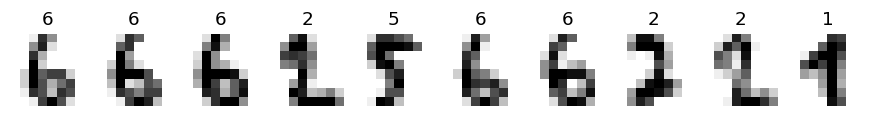

In [31]:
from sklearn.datasets import load_digits

digits = load_digits()
Xall = digits.data.T / 16.0                     # (64, 1797), dans [0, 1]
Yall = np.eye(10)[:, digits.target]             # (10, 1797), one-hot
rng = np.random.default_rng(0)
perm = rng.permutation(Xall.shape[1])
tr, te = perm[:1347], perm[1347:]
Xtr, Ytr, Xte, Yte = Xall[:, tr], Yall[:, tr], Xall[:, te], Yall[:, te]
print("train :", Xtr.shape, " test :", Xte.shape)

fig, axs = plt.subplots(1, 10, figsize=(10, 1.3))
for k, ax in enumerate(axs):
    ax.imshow(Xtr[:, k].reshape(8, 8), cmap="gray_r"); ax.set_title(np.argmax(Ytr[:, k])); ax.axis("off")
plt.show()

On entraîne trois réseaux identiques, avec la même graine, qui ne diffèrent que par l'activation : **ReLU6** (le réseau principal), **ReLU** et **Arctan** (celle des TP). Cela servira à comparer leur robustesse à la quantification.

ReLU6    acc train 1.0000   acc test 0.9889   (3.1s)
ReLU     acc train 1.0000   acc test 0.9911   (3.0s)
Arctan   acc train 1.0000   acc test 0.9933   (4.3s)


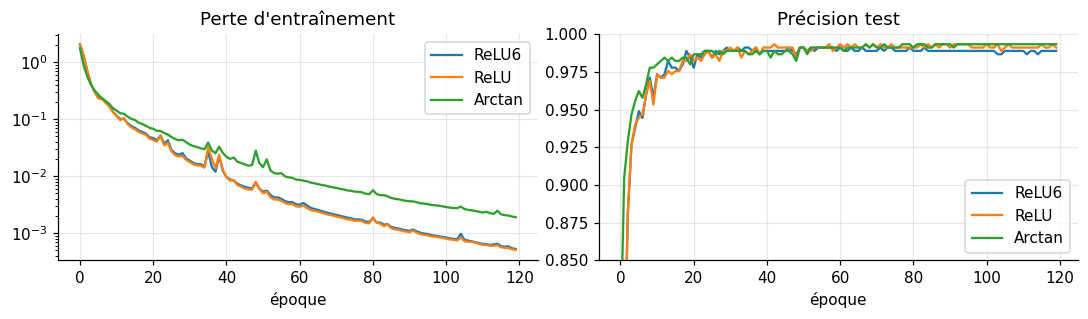

In [32]:
SIZES = [64, 128, 64, 32, 10]
nets, hists = {}, {}
for name, act in [("ReLU6", ReLU6), ("ReLU", ReLU), ("Arctan", Arctan)]:
    np.random.seed(1)
    nets[name] = make_mlp(SIZES, act)
    t0 = time.time()
    hists[name] = train(nets[name], Xtr, Ytr, Xte, Yte, epochs=120, batch=64, lr=1e-3, seed=1)
    print(f"{name:7s}  acc train {hists[name]['acc_train'][-1]:.4f}   acc test {hists[name]['acc_test'][-1]:.4f}   ({time.time()-t0:.1f}s)")

net = nets["ReLU6"]          # réseau principal pour la suite
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for name in nets:
    axs[0].semilogy(hists[name]["loss"], label=name)
    axs[1].plot(hists[name]["acc_test"], label=name)
axs[0].set_title("Perte d'entraînement"); axs[1].set_title("Précision test"); axs[1].set_ylim(0.85, 1.0)
for ax in axs: ax.set_xlabel("époque"); ax.legend()
plt.tight_layout(); plt.show()

Une fois arrivés à ce point on se trouve avce trois réseaux différents qui suivent le schéma suivant

Couche	Entrée → sortie	Paramètres

1	Dense(64, 128)	64 → 128	A : 128×64, b : 128 → 8 320

2	φ	128 → 128	0

3	Dense(128, 64)	128 → 64	A : 64×128, b : 64 → 8 256

4	φ	64 → 64	0

5	Dense(64, 32)	64 → 32	A : 32×64, b : 32 → 2 080

6	φ	32 → 32	0

7	Dense(32, 10)	32 → 10 (logits)	A : 10×32, b : 10 → 330
	Total		18 986

Concrètement :
nets["ReLU6"] = Sequential([Dense(64,128), ReLU6(), Dense(128,64), ReLU6(), Dense(64,32), ReLU6(), Dense(32,10)])

Les couches de tailles différentes (fan-in de 64, 128, 64 et 32) permettent de vérifier si la taille 
d’une couche influe sur son erreur de quantification.
Quatre couches donnent une vraie chaîne le long de laquelle l’erreur peut se propager et s’accumuler.

## 4. Section 2.1 : le schéma de quantification affine

### 4.1 Définition
Le papier impose que toute l'arithmétique se fasse sur les entiers $q$, sans table de correspondance. Cela force une relation **affine** entre l'entier $q$ et le réel $r$ (éq. 1) :

$$\boxed{r = S\,(q - Z)}$$

Pour une quantification sur $B$ bits non signée, $q \in \{0,\dots,2^B-1\}$. Le réel couvert va de $r_{\min} = S(0 - Z)$ à $r_{\max} = S(2^B-1-Z)$.    

**Choix de $(S, Z)$ à partir d'une plage $[a, b]$** (celle de gemmlowp/TFLite) :
1. On élargit la plage pour qu'elle contienne 0 : $a \leftarrow \min(a, 0)$, $b \leftarrow \max(b, 0)$.
2. $S = \dfrac{b-a}{2^B-1}$.
3. $Z = \mathrm{round}\!\left(-a/S\right)$, borné à $[0, 2^B-1]$. C'est le « *nudging* » : en arrondissant $Z$ à un entier, on garantit que **le réel 0 est représenté exactement** par $q = Z$.    On veut que la borne basse de la plage corresponde au plus petit entier (pour r=a, q=0).

**Pourquoi 0 doit être exact ?** Le *padding* par des zéros (convolutions) et surtout les ReLU produisent énormément de zéros. Si 0 n'était pas exactement représentable, chacun porterait une petite erreur, toujours la même : un **biais systématique** qui s'accumulerait.

**Quantification / déquantification :**
$$q = \mathrm{clamp}\big(\mathrm{round}(r/S) + Z,\ 0,\ 2^B-1\big), \qquad \hat r = S(q-Z)$$

Pour une valeur dans la plage, l'erreur $\hat r - r$ est bornée par $S/2$. Hors plage, elle est écrêtée (*clipping*).

### 4.2 Le tampon quantifié
Le papier résume cela par la structure `QuantizedBuffer { vector<QType> q; float S; QType Z; }`. On fait pareil, avec un couple $(S,Z)$ par tableau (un pour les poids d'une couche, un pour ses activations).

In [33]:
def choose_qparams(rmin, rmax, bits=8):
    # Plage [rmin, rmax] -> (S, Z) avec 0 exactement représentable (nudging de gemmlowp).
    qmin, qmax = 0, 2**bits - 1
    rmin, rmax = min(float(rmin), 0.0), max(float(rmax), 0.0)
    if rmax == rmin:                       # tableau identiquement nul
        return 1.0, 0
    S = (rmax - rmin) / (qmax - qmin)
    Z = int(np.clip(np.round(qmin - rmin / S), qmin, qmax))
    return S, Z

def quantize(r, S, Z, bits=8):
    return np.clip(np.round(r / S) + Z, 0, 2**bits - 1).astype(np.int64)

def dequantize(q, S, Z):
    return S * (np.asarray(q, dtype=np.float64) - Z)

def fake_quant(r, rmin, rmax, bits=8):
    # Quantifie puis déquantifie : la valeur réelle que verra le réseau entier.
    S, Z = choose_qparams(rmin, rmax, bits)
    return dequantize(quantize(r, S, Z, bits), S, Z)

# Exemple : les poids de la première couche
A1 = net.list_layers[0].A
S, Z = choose_qparams(A1.min(), A1.max(), 8)
qA1 = quantize(A1, S, Z, 8)
err = dequantize(qA1, S, Z) - A1
print(f"plage des poids : [{A1.min():.4f}, {A1.max():.4f}]")
print(f"S = {S:.6f}   Z = {Z}   q dans [{qA1.min()}, {qA1.max()}]")
print(f"le réel 0 donne q = {quantize(np.array(0.0), S, Z)} -> {dequantize(quantize(np.array(0.0), S, Z), S, Z)} (exact)")
print(f"erreur max = {np.abs(err).max():.6f}   (borne S/2 = {S/2:.6f})")
print(f"écart-type de l'erreur = {err.std():.6f}   (théorie bruit uniforme S/sqrt(12) = {S/np.sqrt(12):.6f})")

plage des poids : [-0.7355, 0.7578]
S = 0.005856   Z = 126   q dans [0, 255]
le réel 0 donne q = 126 -> 0.0 (exact)
erreur max = 0.002928   (borne S/2 = 0.002928)
écart-type de l'erreur = 0.001701   (théorie bruit uniforme S/sqrt(12) = 0.001691)


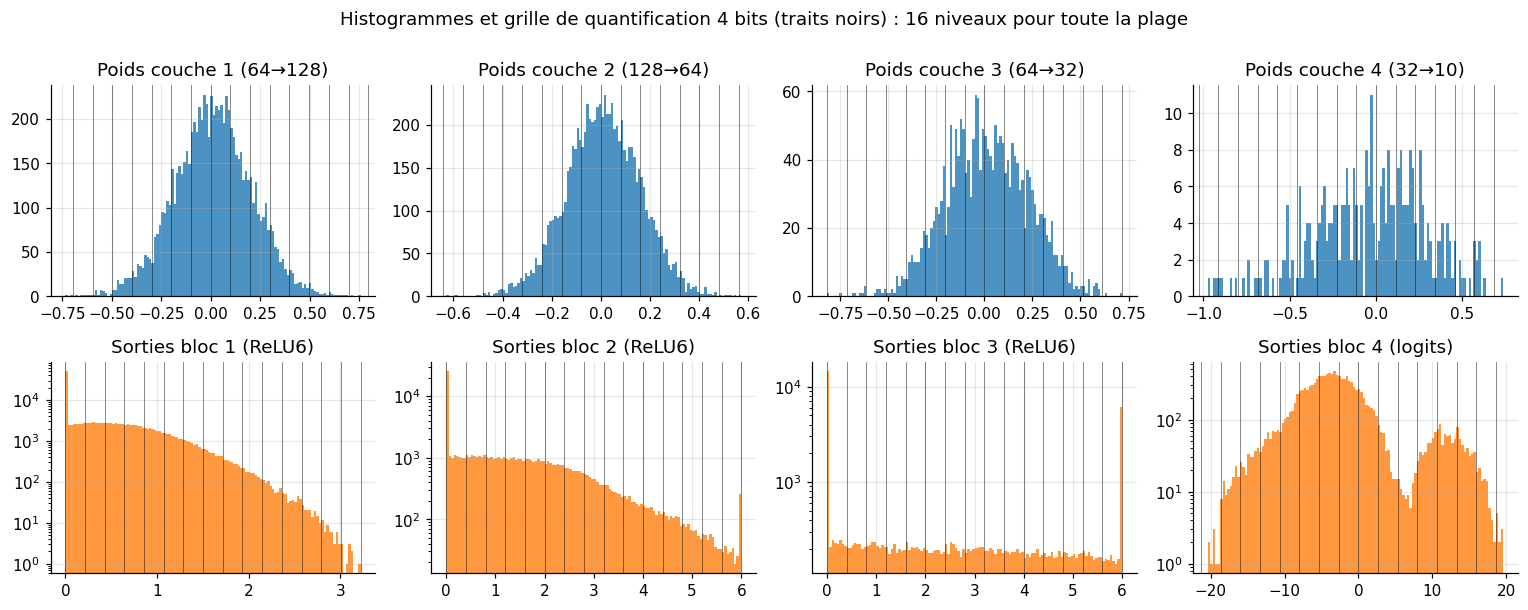

In [34]:
# Visualisation : grille de quantification sur les poids et sur les activations
_, outs = net.forward(Xtr, record=True)
blocks = get_blocks(net)
act_outs = [o for L, o in zip(net.list_layers, outs) if not isinstance(L, Dense) or L is net.list_layers[-1]]

fig, axs = plt.subplots(2, 4, figsize=(14, 5.5))
for i, (dense, act) in enumerate(blocks):
    W = dense.A.ravel()
    S, Z = choose_qparams(W.min(), W.max(), 4)
    ax = axs[0, i]
    ax.hist(W, bins=120, color="tab:blue", alpha=0.8)
    for g in dequantize(np.arange(16), S, Z): ax.axvline(g, color="k", lw=0.5, alpha=0.6)
    ax.set_title(f"Poids couche {i+1} ({dense.A.shape[1]}→{dense.A.shape[0]})")
    a = act_outs[i].ravel()
    S, Z = choose_qparams(a.min(), a.max(), 4)
    ax = axs[1, i]
    ax.hist(a, bins=120, color="tab:orange", alpha=0.8, log=True)
    for g in dequantize(np.arange(16), S, Z): ax.axvline(g, color="k", lw=0.5, alpha=0.6)
    ax.set_title(f"Sorties bloc {i+1}" + (" (logits)" if act is None else f" ({type(act).__name__})"))
fig.suptitle("Histogrammes et grille de quantification 4 bits (traits noirs) : 16 niveaux pour toute la plage", y=1.0)
plt.tight_layout(); plt.show()

**Lecture.** Les poids sont à peu près gaussiens et centrés : la grille est uniforme, donc les niveaux extrêmes servent peu, alors que la majorité des poids se partagent quelques niveaux au centre. Les activations ReLU6 sont positives avec un énorme pic à 0 (échelle log) : grâce au *nudging*, ce pic est représenté exactement. Au bloc 3, une partie des neurones sature à 6 : comme la plage calibrée est exactement $[0,6]$, ce second pic tombe lui aussi pile sur un niveau de la grille. Les logits (dernier bloc) sont signés et plus étalés.

Le point clé pour la suite : **une seule échelle par tableau**. Si quelques valeurs extrêmes étirent la plage, le pas $S$ grandit pour *toutes* les valeurs. Ce sera la cause principale de dégradation des couches (partie 9).

## 5. Section 2.2 : produit matriciel entier

### 5.1 La dérivation
On veut $r_3 = r_1 r_2$, avec $r_1 = A$ (poids, $q\times p$) et $r_2 = X$ (activations, $p\times n$). C'est exactement la convention du TP, où les données sont en colonnes. En remplaçant chaque réel par $S_\alpha(q_\alpha - Z_\alpha)$ (éq. 2-3) :

$$S_3\big(q_3^{(i,k)} - Z_3\big) = \sum_{j=1}^{p} S_1\big(q_1^{(i,j)} - Z_1\big)\,S_2\big(q_2^{(j,k)} - Z_2\big)$$

d'où (éq. 4-5)

$$q_3^{(i,k)} = Z_3 + M \sum_{j=1}^{p}\big(q_1^{(i,j)}-Z_1\big)\big(q_2^{(j,k)}-Z_2\big), \qquad M = \frac{S_1 S_2}{S_3}.$$

**Tout est entier sauf $M$.** Mais $M$ ne dépend que des échelles, connues avant l'inférence : on le calcule **hors ligne**.

### 5.2 $M$ en virgule fixe
Empiriquement $M \in (0,1)$. On l'écrit (éq. 6)

$$M = 2^{-n} M_0, \qquad M_0 \in [0.5, 1),\ n \ge 0,$$

et on stocke $M_0$ comme un `int32` : $M_0^{\text{int}} = \mathrm{round}(2^{31} M_0) \in [2^{30}, 2^{31})$. Comme $M_0 \ge 0.5$, on a toujours au moins 30 bits de précision relative.

Multiplier un accumulateur `int32` par $M$ devient alors deux opérations entières :
1. **multiplication virgule fixe** par $M_0$ : `SaturatingRoundingDoublingHighMul(acc, M0_int)` $\approx \mathrm{round}(\text{acc}\cdot M_0^{\text{int}} / 2^{31})$. C'est l'instruction ARM NEON `SQRDMULH` (annexe B) ;
2. **décalage à droite de $n$ bits avec arrondi au plus proche** : `RoundingDivideByPOT(x, n)`. Attention : un simple `>>` arrondit vers $-\infty$, ce qui introduit un biais (on le mesure en partie 10).

On reproduit fidèlement les deux fonctions de gemmlowp en NumPy (`int64` pour les intermédiaires).

In [35]:
INT32_MIN, INT32_MAX = -2**31, 2**31 - 1

def quantize_multiplier(M):
    # M réel > 0  ->  (M0_int, n) tels que M ≈ M0_int * 2^-31 * 2^-n, M0_int dans [2^30, 2^31).
    mant, exp = np.frexp(M)            # M = mant * 2^exp, mant dans [0.5, 1)
    M0 = int(np.round(mant * 2**31))
    if M0 == 2**31:                     # cas limite de l'arrondi
        M0 //= 2; exp += 1
    return M0, -int(exp)                # n = -exp (n < 0 si M >= 1)

def srdhm(a, b):
    # SaturatingRoundingDoublingHighMul de gemmlowp (= SQRDMULH) : round(a*b / 2^31), entiers 32 bits.
    a = np.asarray(a, dtype=np.int64); b = np.asarray(b, dtype=np.int64)
    ab = a * b
    nudge = np.where(ab >= 0, 1 << 30, 1 - (1 << 30))
    num = ab + nudge
    res = np.where(num >= 0, num >> 31, -((-num) >> 31))        # division tronquée vers 0 (C++)
    return np.where((a == INT32_MIN) & (b == INT32_MIN), INT32_MAX, res)

def rounding_divide_by_pot(x, n, mode="nearest"):
    # Division par 2^n. 'nearest' : gemmlowp (arrondi au plus proche, ex aequo loin de 0).
    # 'half_up' : comportement de RSHL (ex aequo vers +inf). 'floor' : simple >>.
    x = np.asarray(x, dtype=np.int64); n = np.asarray(n, dtype=np.int64)
    if mode == "floor":
        return x >> n
    if mode == "half_up":
        return (x + np.where(n > 0, np.left_shift(1, np.maximum(n - 1, 0)), 0)) >> n
    mask = np.left_shift(1, n) - 1
    remainder = x & mask
    threshold = (mask >> 1) + (x < 0).astype(np.int64)
    return (x >> n) + (remainder > threshold).astype(np.int64)

def multiply_by_quantized_multiplier(acc, M0, n, mode="nearest"):
    n = np.asarray(n, dtype=np.int64)
    left = np.maximum(-n, 0)                   # si M >= 1 : décalage à gauche préalable
    acc = np.left_shift(np.asarray(acc, dtype=np.int64), left)
    return rounding_divide_by_pot(srdhm(acc, M0), np.maximum(n, 0), mode)

In [36]:
# Tests : la multiplication entière doit coller à round(acc * M)
rng = np.random.default_rng(0)
for M in [0.000731, 0.0123, 0.37, 0.9999]:
    M0, n = quantize_multiplier(M)
    acc = rng.integers(-2**24, 2**24, size=100_000)
    ref = np.round(acc * M).astype(np.int64)
    got = multiply_by_quantized_multiplier(acc, M0, n)
    print(f"M = {M:<8}  M0_int = {M0:>10d}  n = {n:2d}   M0_int·2^-31·2^-n = {M0 * 2.0**-31 * 2.0**-n:.10f}"
          f"   |écart| max = {np.abs(got - ref).max()}   écart moyen = {np.mean(got - ref):+.4f}")

print("\nArrondi des ex aequo : -12 / 2^3 = -1.5 (exemple de l'annexe B) et +12 / 2^3 = +1.5")
for mode in ["nearest", "half_up", "floor"]:
    print(f"  {mode:8s} -> {rounding_divide_by_pot(np.array(-12), 3, mode):>3d}   {rounding_divide_by_pot(np.array(12), 3, mode):>3d}")

M = 0.000731  M0_int = 1607486000  n = 10   M0_int·2^-31·2^-n = 0.0007310000   |écart| max = 1   écart moyen = +0.0000
M = 0.0123    M0_int = 1690499128  n =  6   M0_int·2^-31·2^-n = 0.0123000000   |écart| max = 1   écart moyen = +0.0001
M = 0.37      M0_int = 1589137900  n =  1   M0_int·2^-31·2^-n = 0.3700000001   |écart| max = 1   écart moyen = +0.0007
M = 0.9999    M0_int = 2147268900  n =  0   M0_int·2^-31·2^-n = 0.9999000002   |écart| max = 1   écart moyen = -0.0000

Arrondi des ex aequo : -12 / 2^3 = -1.5 (exemple de l'annexe B) et +12 / 2^3 = +1.5
  nearest  ->  -2     2
  half_up  ->  -1     2
  floor    ->  -2     1


**Lecture.** L'écart avec l'arrondi flottant est d'au plus 1 et en moyenne nul : la multiplication entière est fidèle. On retrouve aussi l'exemple de l'annexe B : $-12/2^3 = -1.5$ doit donner $-2$ (arrondi au plus proche, ex aequo loin de zéro), alors que l'instruction `RSHL` (`half_up`) donne $-1$. Le simple `>>` (`floor`) tombe juste sur $-1.5$ par hasard, mais donne $1$ au lieu de $2$ sur $+1.5$, et plus généralement arrondit toujours vers le bas.

## 6. Section 2.3 : gestion efficace des zero-points

Développer l'éq. 4 brutalement coûte $2N^3$ soustractions $(q - Z)$, et oblige à passer en 16 bits. Le papier distribue le produit (éq. 7-8) :

$$\sum_j (q_1^{(i,j)}-Z_1)(q_2^{(j,k)}-Z_2) = \underbrace{\sum_j q_1^{(i,j)} q_2^{(j,k)}}_{\text{cœur } O(N^3)} \;-\; Z_1\, a_2^{(k)} \;-\; Z_2\, \bar a_1^{(i)} \;+\; N Z_1 Z_2$$

avec $a_2^{(k)} = \sum_j q_2^{(j,k)}$ (sommes des colonnes d'activations) et $\bar a_1^{(i)} = \sum_j q_1^{(i,j)}$ (sommes des lignes de poids).

- Le cœur $\sum_j q_1 q_2$ est un produit matriciel **standard** sur des `uint8` bruts, accumulé en `int32` : `int32 += uint8 * uint8`.
- Les corrections coûtent $O(N^2)$.
- Mieux : $\bar a_1$ ne dépend que des **poids**, il est calculé **une fois hors ligne**.

On vérifie l'égalité exacte et on compte les opérations.

In [37]:
rng = np.random.default_rng(1)
q_, p_, n_ = 128, 64, 500
q1 = rng.integers(0, 256, (q_, p_)); Z1 = 131        # poids uint8
q2 = rng.integers(0, 256, (p_, n_)); Z2 = 0          # activations uint8 (après ReLU : Z = 0 souvent)

t0 = time.perf_counter(); naive = (q1 - Z1) @ (q2 - Z2); t_naive = time.perf_counter() - t0
abar1 = q1.sum(axis=1, keepdims=True)                # hors ligne
t0 = time.perf_counter()
core = q1 @ q2
a2 = q2.sum(axis=0, keepdims=True)
fact = core - Z1 * a2 - Z2 * abar1 + p_ * Z1 * Z2
t_fact = time.perf_counter() - t0

print("égalité exacte :", np.array_equal(naive, fact))
print(f"opérations naïves : {2*q_*p_*n_:,} soustractions + produit ; factorisé : produit + {p_*n_ + 3*q_*n_:,} op. de correction")
print(f"plage du cœur : [{core.min():,}, {core.max():,}]  <  2^31 = {2**31:,}  -> l'accumulateur int32 ne déborde pas")
print(f"(temps NumPy : naïf {t_naive*1e3:.1f} ms, factorisé {t_fact*1e3:.1f} ms — non représentatif du matériel, voir conclusion)")

égalité exacte : True
opérations naïves : 8,192,000 soustractions + produit ; factorisé : produit + 224,000 op. de correction
plage du cœur : [640,694, 1,634,119]  <  2^31 = 2,147,483,648  -> l'accumulateur int32 ne déborde pas
(temps NumPy : naïf 10.3 ms, factorisé 11.3 ms — non représentatif du matériel, voir conclusion)


## 7. Section 2.4 : couche fusionnée et réseau 100 % entier

### 7.1 Une couche entière complète
Le papier fusionne Dense + biais + activation en une seule opération qui prend un tenseur `uint8` et rend un tenseur `uint8`. Pour une couche $y = \phi(Ax + b)$ :

1. **Accumulation** `int32` : cœur $\sum q_W q_x$ + corrections de zero-points (éq. 7).
2. **Biais** quantifié en `int32` avec $S_{\text{bias}} = S_W S_x$ et $Z_{\text{bias}} = 0$ (éq. 11) : il a la **même échelle que l'accumulateur**, on l'ajoute directement. Le biais est en 32 bits car chaque coefficient s'ajoute à beaucoup de sorties : une erreur dessus agirait comme un décalage systématique.
3. **Mise à l'échelle** : multiplication par $M = S_W S_x / S_y$ (virgule fixe + décalage), puis $+Z_y$.
4. **Conversion saturée** vers `uint8` : écrêtage à $[0, 255]$.
5. **Activation** : ReLU et ReLU6 ne sont que des écrêtages supplémentaires à $[q(0), q(6)]$. Si la plage de sortie a été calibrée après l'activation, cet écrêtage est **déjà inclus** dans l'étape 4 (remarque du papier, vérifiée plus bas).

Pour une activation non linéaire générale (Arctan, sigmoïde), le papier renvoie à des implémentations en virgule fixe (annexe A.1). Nous prenons un raccourci honnête : une **table de 256 entrées** `uint8 → uint8`, calculée hors ligne. C'est purement entier à l'inférence, mais c'est une étape d'arrondi supplémentaire (on quantifie aussi la pré-activation).

### 7.2 Calibration des plages
Les poids ont une plage connue. Pour les activations, on fait passer un **jeu de calibration** (ici l'ensemble d'entraînement) dans le réseau flottant et on relève min et max à la sortie de chaque bloc. Le papier, en section 3.1, utilise des moyennes glissantes (EMA) pendant l'entraînement ; en post-training, le min/max sur un lot de calibration est l'équivalent standard.

L'**entrée** est quantifiée sur 8 bits (c'est l'image capteur). Pour les chiffres, les pixels n'ont que 17 valeurs (0 à 16), donc cette étape est quasiment sans perte.

In [38]:
FUSABLE = (ReLU, ReLU6)

def calibrate(net, X):
    ranges, z = [], X
    for dense, act in get_blocks(net):
        pre = dense.forward(z)
        out = act.forward(pre) if act is not None else pre
        ranges.append({"inp": (z.min(), z.max()), "pre": (pre.min(), pre.max()), "out": (out.min(), out.max())})
        z = out
    return ranges


class QDense:
    # Couche Dense + biais + (ReLU/ReLU6) fusionnée, 100 % entière à l'inférence.
    def __init__(self, dense, S_in, Z_in, S_out, Z_out, bits_w=8, bits_a=8, act=None,
                 per_channel=False, rounding="nearest", bias_mode="int32"):
        A, b = dense.A, dense.b[:, 0]
        q, p = A.shape
        # --- quantification des poids (hors ligne) ---
        if per_channel:     # une échelle par neurone de sortie (extension, partie 10)
            qp = [choose_qparams(row.min(), row.max(), bits_w) for row in A]
        else:               # une échelle pour toute la matrice (papier)
            qp = [choose_qparams(A.min(), A.max(), bits_w)] * q
        self.S_W = np.array([s for s, _ in qp])
        self.Z_W = np.array([z for _, z in qp], dtype=np.int64)
        self.qW = quantize(A, self.S_W[:, None], self.Z_W[:, None], bits_w).astype(np.uint8)   # stockage 8 bits
        # --- biais int32, échelle S_W * S_in, zero-point 0 (éq. 11) ---
        S_bias = self.S_W * S_in
        if bias_mode == "int32":
            self.qb = np.round(b / S_bias).astype(np.int64)
        else:                           # contre-exemple : biais sur `bias_mode` bits avec sa propre échelle
            sb, zb = choose_qparams(b.min(), b.max(), bias_mode)
            self.qb = np.round(dequantize(quantize(b, sb, zb, bias_mode), sb, zb) / S_bias).astype(np.int64)
        assert np.abs(self.qb).max() < 2**31
        # --- multiplicateur M = S_W S_in / S_out en virgule fixe (hors ligne) ---
        self.M = S_bias / S_out
        mq = [quantize_multiplier(m) for m in self.M]
        self.M0 = np.array([m for m, _ in mq], dtype=np.int64)[:, None]
        self.shift = np.array([s for _, s in mq], dtype=np.int64)[:, None]
        # --- constantes hors ligne pour les zero-points (éq. 7-8) ---
        self.abar1 = self.qW.astype(np.int64).sum(axis=1)[:, None]
        self.S_in, self.Z_in, self.S_out, self.Z_out, self.p = S_in, Z_in, S_out, Z_out, p
        self.bits_a, self.rounding = bits_a, rounding
        # --- bornes de l'activation fusionnée ---
        qmax = 2**bits_a - 1
        self.lo, self.hi = 0, qmax
        if isinstance(act, FUSABLE): self.lo = max(0, Z_out)
        if isinstance(act, ReLU6):   self.hi = min(qmax, int(np.round(6 / S_out)) + Z_out)
        self.act_name = type(act).__name__ if act is not None else "—"

    def accumulate(self, qx):
        qx = qx.astype(np.int64)
        core = self.qW.astype(np.int64) @ qx                     # int32 += uint8 * uint8
        a2 = qx.sum(axis=0, keepdims=True)
        acc = (core - self.Z_in * self.abar1 - self.Z_W[:, None] * a2
               + self.p * self.Z_W[:, None] * self.Z_in + self.qb[:, None])
        assert np.abs(acc).max() < 2**31, "débordement de l'accumulateur int32"
        return acc

    def forward(self, qx):
        acc = self.accumulate(qx)
        y = multiply_by_quantized_multiplier(acc, self.M0, self.shift, self.rounding) + self.Z_out
        y_sat = np.clip(y, 0, 2**self.bits_a - 1)                   # cast saturé vers uint8
        y_act = np.clip(y_sat, self.lo, self.hi)                    # activation fusionnée
        self.extra_clamp_frac = np.mean(y_act != y_sat)             # ce que l'activation ajoute au cast
        return y_act


class QLUT:
    # Activation non linéaire générale : table uint8 -> uint8 calculée hors ligne.
    def __init__(self, act, S_in, Z_in, S_out, Z_out, bits=8):
        grid = np.arange(2**bits)
        self.table = quantize(act.phi(dequantize(grid, S_in, Z_in)), S_out, Z_out, bits)
        self.S_out, self.Z_out = S_out, Z_out
        self.act_name = type(act).__name__ + " (table)"
    def forward(self, qx):
        return self.table[qx]


class QuantizedNet:
    def __init__(self, net, X_calib, bits_w=8, bits_a=8, bits_in=8, per_channel=False,
                 rounding="nearest", bias_mode="int32"):
        self.ranges = calibrate(net, X_calib)
        self.bits_in = bits_in
        self.S_in, self.Z_in = choose_qparams(*self.ranges[0]["inp"], bits_in)
        self.stages, self.block_end = [], []
        S, Z = self.S_in, self.Z_in
        kw = dict(bits_w=bits_w, bits_a=bits_a, per_channel=per_channel, rounding=rounding, bias_mode=bias_mode)
        for (dense, act), rg in zip(get_blocks(net), self.ranges):
            if act is None or isinstance(act, FUSABLE):
                So, Zo = choose_qparams(*rg["out"], bits_a)
                self.stages.append(QDense(dense, S, Z, So, Zo, act=act, **kw))
            else:
                Sp, Zp = choose_qparams(*rg["pre"], bits_a)
                self.stages.append(QDense(dense, S, Z, Sp, Zp, act=None, **kw))
                self.block_end.append(False)
                So, Zo = choose_qparams(*rg["out"], bits_a)
                self.stages.append(QLUT(act, Sp, Zp, So, Zo, bits_a))
            self.block_end.append(True)
            S, Z = So, Zo
        self.S_out, self.Z_out = S, Z
        self.qparams = [(st.S_out, st.Z_out) if isinstance(st, QDense) else None for st in self.stages]

    def forward_int(self, X, record=False):
        q = quantize(X, self.S_in, self.Z_in, self.bits_in)    # seule conversion float -> int (capteur)
        rec = []
        for st in self.stages:
            q = st.forward(q)
            rec.append(q)
        return (q, rec) if record else q

    def predict(self, X):
        # argmax sur les logits entiers : r = S(q - Z) avec S > 0 est croissante, l'argmax est inchangé
        return np.argmax(self.forward_int(X), axis=0)

    def block_outputs(self, X):
        # Sorties déquantifiées de chaque bloc, pour comparer au flottant.
        _, rec = self.forward_int(X, record=True)
        return [dequantize(q, st.S_out, st.Z_out) for st, q, end in zip(self.stages, rec, self.block_end) if end]

    def size_bytes(self):
        n = 0
        for st in self.stages:
            if isinstance(st, QDense):
                k = len(np.unique(st.M0))                      # 1 multiplicateur par matrice, ou 1 par neurone
                n += st.qW.size * 1 + st.qb.size * 4 + k * (4 + 1 + 1)   # poids uint8 + biais int32 + (M0, n, Z_W)
            else:
                n += st.table.size
        return n

In [39]:
qnet = QuantizedNet(net, Xtr, bits_w=8, bits_a=8)

float_size = sum(p.size for p in net.list_params) * 4      # en float32
print(f"Taille du modèle : float32 {float_size/1024:.1f} Ko  ->  quantifié {qnet.size_bytes()/1024:.1f} Ko "
      f"(÷{float_size/qnet.size_bytes():.2f})\n")

print(f"{'bloc':<5}{'forme':<11}{'act.':<8}{'S_W':>10}{'Z_W':>6}{'S_y':>10}{'Z_y':>6}{'M':>11}{'M0_int':>12}{'n':>4}{'[lo,hi]':>12}")
for i, st in enumerate(qnet.stages):
    print(f"{i+1:<5}{str(st.qW.shape):<11}{st.act_name:<8}{st.S_W[0]:>10.5f}{st.Z_W[0]:>6d}{st.S_out:>10.5f}{st.Z_out:>6d}"
          f"{st.M[0]:>11.6f}{st.M0[0,0]:>12d}{st.shift[0,0]:>4d}{str((st.lo, st.hi)):>12}")
print(f"\nEntrée : S = {qnet.S_in:.6f} (= 1/255), Z = {qnet.Z_in}")

Taille du modèle : float32 74.2 Ko  ->  quantifié 19.2 Ko (÷3.85)

bloc forme      act.           S_W   Z_W       S_y   Z_y          M      M0_int   n     [lo,hi]
1    (128, 64)  ReLU6      0.00586   126   0.01263     0   0.001818  1998807476   9    (0, 255)
2    (64, 128)  ReLU6      0.00471   134   0.02353     0   0.002528  1389837579   8    (0, 255)
3    (32, 64)   ReLU6      0.00602   136   0.02353     0   0.006023  1655700563   7    (0, 255)
4    (10, 32)   —          0.00671   145   0.15683   130   0.001007  1106864671   9    (0, 255)

Entrée : S = 0.003922 (= 1/255), Z = 0


On retrouve ce que décrit le papier : tous les $M$ sont dans $(0,1)$ et donc s'écrivent $2^{-n}M_0$ avec $n \ge 0$ ; après une ReLU6 calibrée, $Z_y = 0$ (le 0 réel est l'entier 0).

### 7.3 Trace d'une inférence 100 % entière
On suit une image à travers le réseau en affichant le type et la plage de chaque tenseur intermédiaire. Aucun flottant n'apparaît après la quantification de l'entrée.

In [40]:
x0 = Xte[:, :1]
q = quantize(x0, qnet.S_in, qnet.Z_in, 8).astype(np.uint8)
print(f"entrée            {q.dtype}   plage [{q.min()}, {q.max()}]")
for i, st in enumerate(qnet.stages):
    acc = st.accumulate(q)
    print(f"bloc {i+1} accum.    int32   plage [{acc.min()}, {acc.max()}]   (stocké int64 dans NumPy, vérifié < 2^31)")
    q = st.forward(q).astype(np.uint8)
    print(f"bloc {i+1} sortie    {q.dtype}   plage [{q.min()}, {q.max()}]")
print("\nlogits entiers :", q.ravel())
print("prédiction entière :", np.argmax(q), " | flottante :", np.argmax(net.forward(x0)), " | vérité :", np.argmax(Yte[:, 0]))
print("\nFraction des sorties modifiées par l'écrêtage ReLU6 au-delà du cast uint8 :",
      [f"{st.extra_clamp_frac:.3f}" for st in qnet.stages])

entrée            uint8   plage [0, 255]
bloc 1 accum.    int32   plage [-105473, 117349]   (stocké int64 dans NumPy, vérifié < 2^31)
bloc 1 sortie    uint8   plage [0, 213]
bloc 2 accum.    int32   plage [-40246, 85572]   (stocké int64 dans NumPy, vérifié < 2^31)
bloc 2 sortie    uint8   plage [0, 216]
bloc 3 accum.    int32   plage [-44032, 60084]   (stocké int64 dans NumPy, vérifié < 2^31)
bloc 3 sortie    uint8   plage [0, 255]
bloc 4 accum.    int32   plage [-61420, 62823]   (stocké int64 dans NumPy, vérifié < 2^31)
bloc 4 sortie    uint8   plage [68, 193]

logits entiers : [112 108  98 115  91 107  92  68 193 135]
prédiction entière : 8  | flottante : 8  | vérité : 8

Fraction des sorties modifiées par l'écrêtage ReLU6 au-delà du cast uint8 : ['0.000', '0.000', '0.000', '0.000']


La dernière ligne confirme la remarque de la section 2.4 : une fois la plage calibrée après l'activation, l'écrêtage propre à ReLU6 ne fait **plus rien**, il est absorbé par la conversion saturée vers `uint8`.

### 7.4 Résultat principal

In [41]:
def kl_div(P, Q, eps=1e-12):
    return np.mean(np.sum(P * (np.log(P + eps) - np.log(Q + eps)), axis=0))

sm = Softmax()
logits_f = net.forward(Xte)
pred_f = np.argmax(logits_f, axis=0)
pred_q = qnet.predict(Xte)
logits_q = dequantize(qnet.forward_int(Xte), qnet.S_out, qnet.Z_out)

print(f"Précision test flottante     : {accuracy(pred_f, Yte):.4f}")
print(f"Précision test entière 8 bits : {accuracy(pred_q, Yte):.4f}")
print(f"Accord des décisions          : {np.mean(pred_f == pred_q):.4f}  ({np.sum(pred_f != pred_q)} désaccord(s) sur {len(pred_f)})")
print(f"KL(softmax float || softmax quantifié) moyenne : {kl_div(sm.forward(logits_f), sm.forward(logits_q)):.2e}")

Précision test flottante     : 0.9889
Précision test entière 8 bits : 0.9889
Accord des décisions          : 1.0000  (0 désaccord(s) sur 450)
KL(softmax float || softmax quantifié) moyenne : 4.04e-05


## 8. Correspondance simulation flottante / inférence entière

Le papier insiste sur un point : le schéma est défini mathématiquement, puis implémenté **deux fois** — en entiers pour l'inférence, en flottant pour l'entraînement (« *fake quantization* », section 3). Les deux doivent coïncider.

On écrit la version flottante : chaque poids et chaque activation passent par `fake_quant` ($q$ puis $\hat r$), le biais est arrondi sur la grille $S_W S_x$, et tout le reste est du calcul flottant normal. Cette simulation nous servira pour les analyses fines (quantifier une seule couche, seulement les poids, etc.), qui seraient lourdes à écrire en entiers. Avant, on vérifie qu'elle reproduit bien l'inférence entière.

In [42]:
def sim_forward(net, ranges, X, wbits=8, abits=8, bits_in=8, per_channel=False, quant_bias=True):
    # Simulation flottante de la quantification. wbits / abits : entier, None (pas de quantification),
    # ou liste par bloc. Renvoie la liste des sorties de chaque bloc.
    blocks = get_blocks(net); nb = len(blocks)
    wb = wbits if isinstance(wbits, (list, tuple)) else [wbits] * nb
    ab = abits if isinstance(abits, (list, tuple)) else [abits] * nb
    if bits_in:
        S_x, _ = choose_qparams(*ranges[0]["inp"], bits_in)
        z = fake_quant(X, *ranges[0]["inp"], bits_in)
    else:
        S_x, z = None, X
    outs = []
    for i, ((dense, act), rg) in enumerate(zip(blocks, ranges)):
        A, b = dense.A, dense.b
        if wb[i]:
            if per_channel:
                qp = [choose_qparams(r.min(), r.max(), wb[i]) for r in A]
                S_W = np.array([s for s, _ in qp])[:, None]; Z_W = np.array([zz for _, zz in qp])[:, None]
            else:
                s, zz = choose_qparams(A.min(), A.max(), wb[i]); S_W, Z_W = np.full((A.shape[0], 1), s), zz
            A = dequantize(quantize(A, S_W, Z_W, wb[i]), S_W, Z_W)
            if quant_bias and S_x is not None:
                b = np.round(b / (S_W * S_x)) * (S_W * S_x)
        out = A @ z + b
        if act is not None:
            out = act.phi(out)
        if ab[i]:
            S_x, _ = choose_qparams(*rg["out"], ab[i])
            out = fake_quant(out, *rg["out"], ab[i])
        else:
            S_x = None
        outs.append(out); z = out
    return outs

ranges = calibrate(net, Xtr)
sim_outs = sim_forward(net, ranges, Xte, 8, 8)
_, rec = qnet.forward_int(Xte, record=True)
print(f"{'bloc':<6}{'entrées identiques':>20}{'écart max (pas S)':>20}")
for i, (st, q) in enumerate(zip(qnet.stages, rec)):
    q_sim = np.round(sim_outs[i] / st.S_out) + st.Z_out
    print(f"{i+1:<6}{np.mean(q_sim == q):>20.4%}{np.abs(q_sim - q).max():>20.0f}")
print("décisions identiques :", np.mean(np.argmax(sim_outs[-1], 0) == qnet.predict(Xte)))

bloc    entrées identiques   écart max (pas S)
1                 99.9427%                   1
2                 99.5278%                   1
3                 97.8889%                   1
4                 98.4889%                   1
décisions identiques : 1.0


Quasiment tout est identique au bit près. Les rares écarts valent 1 pas de quantification : ils viennent du fait que $M$ est arrondi sur 31 bits en virgule fixe, ce qui déplace exceptionnellement un ex aequo d'arrondi. Pour la suite, la simulation flottante est donc un substitut fiable de l'inférence entière.

## 9. Propagation de l'erreur : quelles couches, pourquoi, comment

### 9.1 Mesure
Pour chaque bloc $\ell$, on compare la sortie quantifiée $\hat a_\ell$ à la sortie flottante $a_\ell$ par le **rapport signal sur bruit de quantification** :

$$\mathrm{SQNR}_\ell = 10\log_{10}\frac{\|a_\ell\|^2}{\|\hat a_\ell - a_\ell\|^2}\ \text{(dB)}$$

Repère utile : pour un signal uniforme sur toute la plage, chaque bit ajouté vaut environ **+6 dB**.

Deux mesures pour séparer naissance et propagation :
- **erreur cumulée** : tout le réseau est quantifié, l'erreur à la couche $\ell$ contient celle héritée des couches précédentes ;
- **erreur locale** : on donne à la couche $\ell$ l'entrée *flottante exacte* (simplement quantifiée), donc on ne voit que l'erreur créée par cette couche.

8 bits  cumulée : [40.9 41.3 41.9 39.1]   locale : [40.9 43.6 44.5 40.8]
6 bits  cumulée : [29.1 29.5 28.4 26.2]   locale : [29.1 31.2 31.9 29.6]
4 bits  cumulée : [16.5 17.8 17.9 13.7]   locale : [16.5 19.5 20.7 16.9]


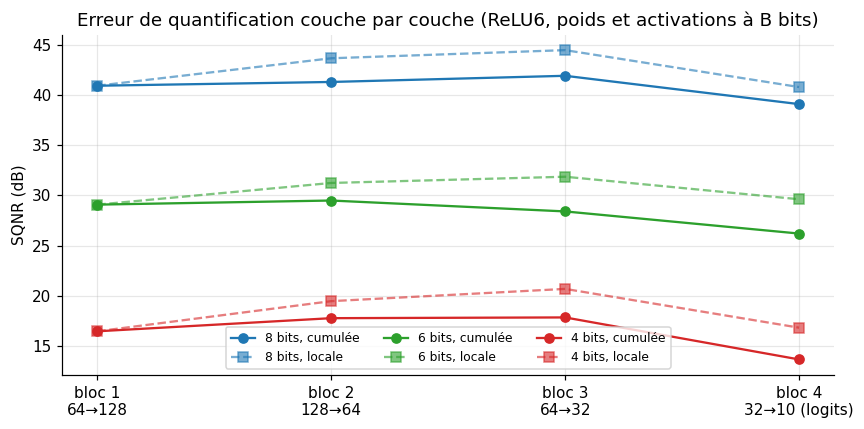

In [43]:
def sqnr(a, ah):
    return 10 * np.log10(np.sum(a**2) / max(np.sum((ah - a)**2), 1e-30))

def float_block_outputs(net, X):
    outs, z = [], X
    for dense, act in get_blocks(net):
        z = dense.forward(z)
        if act is not None: z = act.phi(z)
        outs.append(z)
    return outs

def local_outputs(net, ranges, X, wbits=8, abits=8, bits_in=8):
    # Sortie de chaque bloc quantifié quand on lui donne l'entrée flottante exacte (quantifiée).
    blocks = get_blocks(net); f = float_block_outputs(net, X)
    res = []
    for l in range(len(blocks)):
        sub = Sequential([L for blk in blocks[l:l+1] for L in blk if L is not None])
        inp = X if l == 0 else f[l - 1]
        rg = [{"inp": ranges[l]["inp"], "pre": ranges[l]["pre"], "out": ranges[l]["out"]}]
        res.append(sim_forward(sub, rg, inp, wbits, abits, bits_in=(bits_in if l == 0 else abits))[0])
    return res

f_outs = float_block_outputs(net, Xte)
fig, ax = plt.subplots(figsize=(8, 4))
for bits, c in [(8, "tab:blue"), (6, "tab:green"), (4, "tab:red")]:
    cum = [sqnr(a, ah) for a, ah in zip(f_outs, sim_forward(net, ranges, Xte, bits, bits))]
    loc = [sqnr(a, ah) for a, ah in zip(f_outs, local_outputs(net, ranges, Xte, bits, bits))]
    ax.plot(range(1, 5), cum, "o-", color=c, label=f"{bits} bits, cumulée")
    ax.plot(range(1, 5), loc, "s--", color=c, alpha=0.6, label=f"{bits} bits, locale")
    print(f"{bits} bits  cumulée : {np.round(cum, 1)}   locale : {np.round(loc, 1)}")
ax.set_xticks(range(1, 5)); ax.set_xticklabels(["bloc 1\n64→128", "bloc 2\n128→64", "bloc 3\n64→32", "bloc 4\n32→10 (logits)"])
ax.set_ylabel("SQNR (dB)"); ax.set_title("Erreur de quantification couche par couche (ReLU6, poids et activations à B bits)")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

### 9.2 Pourquoi : un modèle de bruit simple
Considérons la pré-activation $u = Wx + b$ d'une couche. Quantifier ajoute $\Delta W$ aux poids et $\Delta x$ aux entrées. Au premier ordre :

$$\Delta u \approx \Delta W\, x + W\, \Delta x.$$

Si l'erreur d'arrondi est uniforme sur $[-S/2, S/2]$ et indépendante (hypothèse classique, valable à 8 bits), de variance $S^2/12$ :

$$\mathbb E[\Delta u_i^2] \approx \frac{S_W^2}{12}\,\|x\|^2 + \frac{S_x^2}{12}\,\|W_{i,:}\|^2.$$

Divisons par $\mathbb E[u_i^2] \approx p\,\sigma_W^2\,\mathbb E[x^2]$ (poids et entrées peu corrélés). Avec $S = \text{plage}/(2^B-1)$, le **rapport bruit/signal relatif** devient

$$\frac{\mathbb E[\Delta u^2]}{\mathbb E[u^2]} \approx \frac{1}{12(2^B-1)^2}\left(\kappa_W^2 + \kappa_x^2\right), \qquad \kappa = \frac{\text{plage}}{\text{valeur RMS}}.$$

**Conclusion clé :** la taille de la couche $p$ s'élimine. Ce qui compte, c'est le **facteur de crête** $\kappa$ des poids et des entrées, c'est-à-dire **à quel point quelques valeurs extrêmes étirent la plage** par rapport à la valeur typique. Une couche dont les poids ont un outlier, ou dont l'entrée est très creuse (beaucoup de zéros après ReLU, donc RMS faible), sera plus abîmée.

On vérifie ce modèle sur la pré-activation de chaque couche, en local.

In [44]:
def crest(r): return (r.max() - min(r.min(), 0) if r.min() >= 0 else r.max() - r.min()) / np.sqrt(np.mean(r**2))

bits = 6; L = 2**bits - 1
print(f"Modèle de bruit, {bits} bits, pré-activations, mesure locale")
print(f"{'bloc':<6}{'κ_W':>7}{'κ_x':>7}{'SQNR prédit (κ)':>17}{'SQNR prédit (exact)':>21}{'SQNR mesuré':>13}")
x_in = [Xte] + f_outs[:-1]
pred_k, meas = [], []
for l, (dense, act) in enumerate(get_blocks(net)):
    xq_rg = ranges[l]["inp"]
    b_in = 8 if l == 0 else bits
    S_x, _ = choose_qparams(*xq_rg, b_in)
    S_W, _ = choose_qparams(dense.A.min(), dense.A.max(), bits)
    xq = fake_quant(x_in[l], *xq_rg, b_in)
    Wq = fake_quant(dense.A, dense.A.min(), dense.A.max(), bits)
    bq = np.round(dense.b / (S_W * S_x)) * S_W * S_x
    u = dense.A @ x_in[l] + dense.b
    uq = Wq @ xq + bq
    kW, kx = crest(dense.A), crest(x_in[l])
    Lx = 2**b_in - 1
    p_k = -10 * np.log10(kW**2 / (12 * L**2) + kx**2 / (12 * Lx**2))
    mse_pred = S_W**2 / 12 * np.mean(np.sum(x_in[l]**2, 0)) + S_x**2 / 12 * np.mean(np.sum(dense.A**2, 1))
    p_e = 10 * np.log10(np.mean(u**2) / mse_pred)
    m = sqnr(u, uq)
    pred_k.append(p_k); meas.append(m)
    print(f"{l+1:<6}{kW:>7.1f}{kx:>7.1f}{p_k:>17.1f}{p_e:>21.1f}{m:>13.1f}")

Modèle de bruit, 6 bits, pré-activations, mesure locale
bloc      κ_W    κ_x  SQNR prédit (κ)  SQNR prédit (exact)  SQNR mesuré
1         7.6    2.1             29.1                 29.6         29.7
2         8.0    4.2             27.7                 31.2         31.3
3         7.1    3.4             28.8                 31.3         31.4
4         5.2    1.8             31.9                 32.9         34.6


**Lecture.** La prédiction « exacte » (avec $\|x\|^2$ et $\|W_i\|^2$ mesurés) colle à la mesure à 1-2 dB près : l'erreur de quantification se comporte bien comme un bruit additif indépendant. La version en facteurs de crête est plus grossière (elle suppose poids et entrées décorrélés, ce qui est faux après apprentissage), mais elle donne la bonne intuition : **les couches dont l'entrée ou les poids ont un grand facteur de crête perdent le plus de dB**.

- Le **bloc 1** reçoit les pixels quantifiés sur 8 bits avec seulement 17 niveaux utiles : son entrée est quasi exacte, seule l'erreur sur les poids compte.
- Le **bloc 2** a l'entrée au plus grand facteur de crête ($\kappa_x \approx 4$) : les sorties du bloc 1 sont pleines de zéros avec une longue queue jusqu'à 3.2 (voir les histogrammes). La valeur RMS est faible devant la plage, et c'est lui que le modèle en $\kappa$ prédit comme le plus mauvais.
- Le **bloc 4** a au contraire une entrée au facteur de crête faible ($\kappa_x \approx 1.8$) : les sorties du bloc 3 sont souvent à 0 ou saturées à 6, donc la plage est bien remplie. C'est la couche la mieux quantifiée en local.

### 9.3 Comment l'erreur se propage
Comparer erreur locale et erreur cumulée (figure 9.1) montre que l'erreur **s'accumule** : dès le bloc 2, la SQNR cumulée est 2 à 3 dB sous la SQNR locale, quel que soit le nombre de bits. En puissance, les bruits indépendants s'additionnent : chaque couche ajoute son bruit propre au bruit hérité, que la couche linéaire suivante transmet (avec un gain qui dépend de $W$). Les écarts entre 8, 6 et 4 bits sont d'environ 12 dB pour 2 bits, soit les 6 dB par bit attendus.

Deux mécanismes atténuent la propagation :
- la **ReLU/ReLU6** met à zéro les neurones inactifs, et l'erreur qu'ils portaient disparaît avec eux ;
- la **re-quantification** en sortie de chaque couche ne crée pas de nouvelle erreur par-dessus une erreur déjà plus grande que $S/2$ : elle arrondit, elle ne corrige pas.

Ce qui compte au final n'est pas la SQNR mais la **décision** : l'argmax ne change que si l'erreur sur les logits dépasse l'écart entre les deux meilleures classes (la **marge**).

8 bits : 0 décisions changées ; marge médiane des changées = nan, des autres = 10.50
4 bits : 9 décisions changées ; marge médiane des changées = 1.21, des autres = 10.57


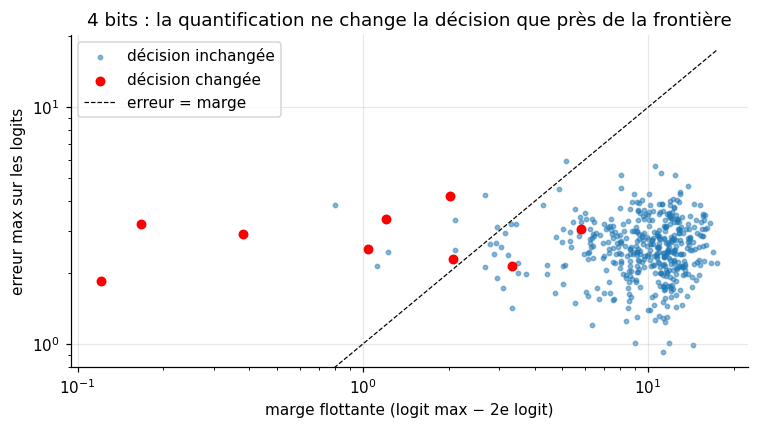

In [45]:
for bits in [8, 4]:
    lq = sim_forward(net, ranges, Xte, bits, bits)[-1]
    pq = np.argmax(lq, 0)
    srt = np.sort(logits_f, axis=0)
    margin = srt[-1] - srt[-2]
    err = np.max(np.abs(lq - logits_f), axis=0)
    flip = pq != pred_f
    print(f"{bits} bits : {flip.sum()} décisions changées ; marge médiane des changées = "
          f"{np.median(margin[flip]) if flip.any() else float('nan'):.2f}, des autres = {np.median(margin[~flip]):.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(margin[~flip], err[~flip], s=8, alpha=0.5, label="décision inchangée")
ax.scatter(margin[flip], err[flip], s=30, color="red", label="décision changée")
lim = max(margin.max(), err.max())
ax.plot([0, lim], [0, lim], "k--", lw=0.8, label="erreur = marge")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("marge flottante (logit max − 2e logit)"); ax.set_ylabel("erreur max sur les logits")
ax.set_title("4 bits : la quantification ne change la décision que près de la frontière"); ax.legend()
plt.tight_layout(); plt.show()

### 9.4 Quelle couche est la plus sensible ?
On quantifie **une seule couche à la fois** à faible précision (3 bits), le reste en flottant, et on sépare l'effet des poids et celui des activations de sortie. On mesure la chute de précision et la divergence KL entre les distributions softmax flottante et quantifiée (plus fine que la précision).

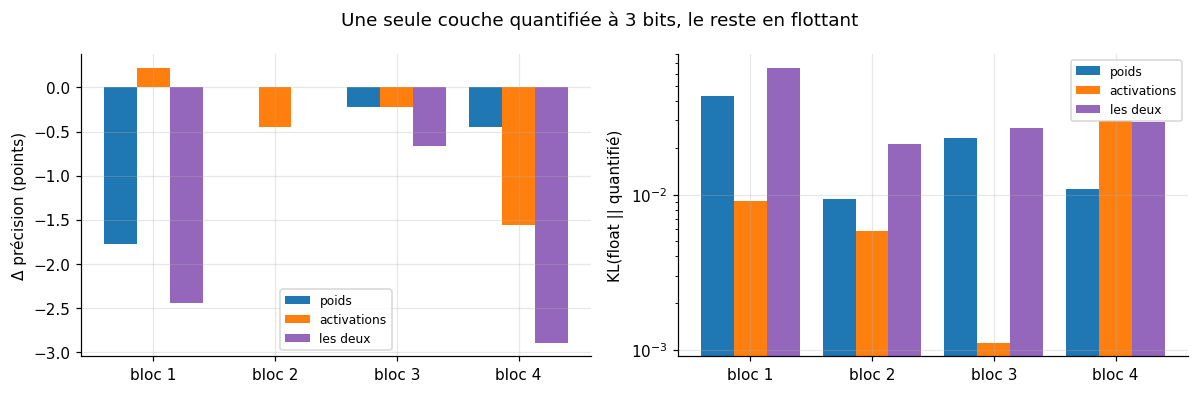

bloc    κ poids  κ sortie  ratio plages par neurone (max/min)
1           7.6       4.2                                 2.0
2           8.0       3.4                                 2.1
3           7.1       1.8                                 1.7
4           5.2       5.8                                 1.3


In [46]:
nb = len(get_blocks(net))
P_f = sm.forward(logits_f)
B = 3
res = {"poids": [], "activations": [], "les deux": []}
for l in range(nb):
    for key, wb, ab in [("poids", B, None), ("activations", None, B), ("les deux", B, B)]:
        wl = [None] * nb; al = [None] * nb
        if wb: wl[l] = wb
        if ab: al[l] = ab
        lq = sim_forward(net, ranges, Xte, wl, al, bits_in=None)[-1]
        res[key].append((accuracy(lq, Yte) - accuracy(logits_f, Yte), kl_div(P_f, sm.forward(lq))))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
w = 0.27
for k, (key, c) in enumerate(zip(res, ["tab:blue", "tab:orange", "tab:purple"])):
    axs[0].bar(np.arange(nb) + (k - 1) * w, [100 * r[0] for r in res[key]], w, color=c, label=key)
    axs[1].bar(np.arange(nb) + (k - 1) * w, [r[1] for r in res[key]], w, color=c, label=key)
for ax in axs:
    ax.set_xticks(range(nb)); ax.set_xticklabels([f"bloc {i+1}" for i in range(nb)]); ax.legend(fontsize=8)
axs[0].set_ylabel("Δ précision (points)"); axs[1].set_ylabel("KL(float || quantifié)"); axs[1].set_yscale("log")
fig.suptitle(f"Une seule couche quantifiée à {B} bits, le reste en flottant"); plt.tight_layout(); plt.show()

print(f"{'bloc':<6}{'κ poids':>9}{'κ sortie':>10}{'ratio plages par neurone (max/min)':>36}")
for l, (dense, act) in enumerate(get_blocks(net)):
    rr = np.ptp(dense.A, axis=1)
    print(f"{l+1:<6}{crest(dense.A):>9.1f}{crest(f_outs[l]):>10.1f}{rr.max()/rr.min():>36.1f}")

**Lecture.** Deux couches se détachent, pour deux raisons différentes.

- **Bloc 1, ses poids.** C'est la couche la plus abîmée par la quantification de ses poids. Elle cumule un facteur de crête des poids parmi les plus élevés et une position défavorable : son erreur traverse les trois couches suivantes, qui la transmettent au lieu de la corriger. Les blocs 2 et 3, au milieu, sont étonnamment robustes : ils sont redondants (128 et 64 neurones pour une information qui tient dans peu de dimensions).
- **Bloc 4, ses activations (les logits).** À 3 bits, les 10 logits n'ont que 8 niveaux possibles. Plusieurs classes tombent sur le même entier et l'argmax départage des ex aequo au hasard. Aucune non-linéarité ne vient ensuite absorber l'erreur : elle va directement dans la décision. C'est pour cela qu'en pratique on garde souvent la **dernière couche en plus haute précision**.

Le papier cite deux causes de dégradation des poids (section 3) : des plages très différentes d'un neurone de sortie à l'autre (plus de 100× dans MobileNet), et des valeurs extrêmes. Ici les plages par neurone restent homogènes (rapport ≈ 2), c'est donc surtout le facteur de crête qui joue. On verra en 10.4 que même ce faible déséquilibre suffit à rendre l'échelle par neurone utile à bas nombre de bits.

### 9.5 Poids contre activations : grille de bits
Comme dans le tableau 4.7 du papier, on fait varier séparément les bits des poids et des activations (pour toutes les couches à la fois).

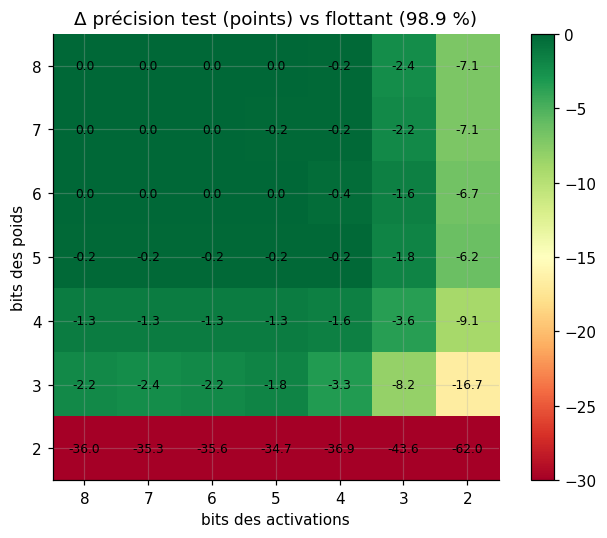

In [47]:
bit_list = [8, 7, 6, 5, 4, 3, 2]
acc_f = accuracy(logits_f, Yte)
grid = np.zeros((len(bit_list), len(bit_list)))
for i, wb in enumerate(bit_list):
    for j, ab in enumerate(bit_list):
        grid[i, j] = 100 * (accuracy(sim_forward(net, ranges, Xte, wb, ab)[-1], Yte) - acc_f)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(grid, cmap="RdYlGn", vmin=-30, vmax=0)
for i in range(len(bit_list)):
    for j in range(len(bit_list)):
        ax.text(j, i, f"{grid[i,j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(bit_list))); ax.set_xticklabels(bit_list); ax.set_xlabel("bits des activations")
ax.set_yticks(range(len(bit_list))); ax.set_yticklabels(bit_list); ax.set_ylabel("bits des poids")
ax.set_title(f"Δ précision test (points) vs flottant ({100*acc_f:.1f} %)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

**Lecture.** Jusqu'à 4-5 bits, la perte est négligeable : 8 bits ont une large marge sur ce problème. À 3 bits, poids et activations coûtent à peu près autant (≈ 2 points chacun). À 2 bits, l'asymétrie est nette : des **poids à 2 bits** détruisent le réseau (≈ −35 points) alors que des **activations à 2 bits** coûtent ≈ 7 points. On retrouve la conclusion du papier (tableaux 4.7-4.8) : les poids sont plus sensibles que les activations. Avec 4 niveaux pour une distribution en cloche, la plupart des poids sont arrondis à la même valeur et la couche perd l'essentiel de ce qu'elle a appris ; les activations ReLU6, elles, sont en majorité des 0 qui restent exacts.

## 10. Détails d'implémentation qui comptent

### 10.1 Le choix de l'activation (tableau 4.3 du papier)
Le papier observe que les réseaux ReLU6 perdent moins que les réseaux ReLU, car ReLU6 impose une plage naturelle $[0,6]$ alors que ReLU laisse les activations s'étaler, avec des plages différentes d'un canal à l'autre. On compare nos trois réseaux, avec l'**inférence entière** réelle (table de correspondance pour Arctan).

act.           8 b       6 b       5 b       4 b       3 b     plage max des activations cachées
ReLU6         +0.0      +0.0      -0.2      -1.6      -8.4     3.2, 6.0, 6.0
ReLU          +0.0      -0.4      +0.0      -2.4     -16.9     3.4, 9.5, 20.2
Arctan        +0.0      +0.0      -0.4      -0.7     -10.4     1.2, 1.4, 1.4


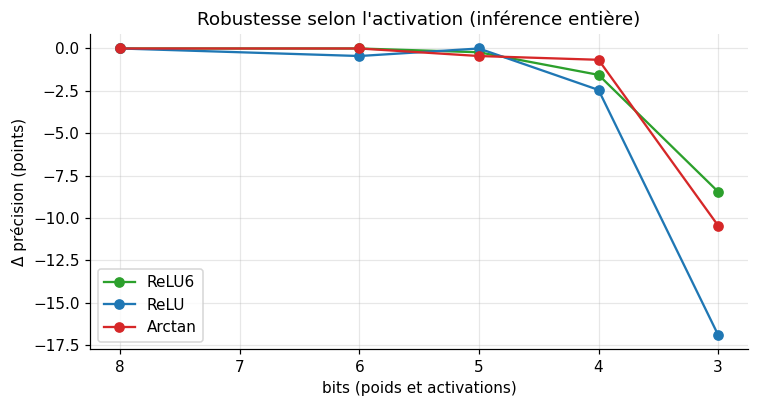

In [48]:
bit_list = [8, 6, 5, 4, 3]
fig, ax = plt.subplots(figsize=(7, 3.8))
print(f"{'act.':<8}" + "".join(f"{b:>8} b" for b in bit_list) + "     plage max des activations cachées")
for name, c in zip(nets, ["tab:green", "tab:blue", "tab:red"]):
    nt = nets[name]; af = accuracy(nt.forward(Xte), Yte)
    accs = [accuracy(QuantizedNet(nt, Xtr, b, b).predict(Xte), Yte) - af for b in bit_list]
    rg = calibrate(nt, Xtr)
    ax.plot(bit_list, 100 * np.array(accs), "o-", color=c, label=name)
    print(f"{name:<8}" + "".join(f"{100*a:>+10.1f}" for a in accs) + "     " + ", ".join(f"{r['out'][1]:.1f}" for r in rg[:-1]))
ax.invert_xaxis(); ax.set_xlabel("bits (poids et activations)"); ax.set_ylabel("Δ précision (points)")
ax.set_title("Robustesse selon l'activation (inférence entière)"); ax.legend(); plt.tight_layout(); plt.show()

**Lecture.** On retrouve le résultat du papier : à 3 bits, le réseau **ReLU perd deux fois plus** que le réseau ReLU6. La dernière colonne donne la raison : les activations ReLU de la 3e couche montent jusqu'à ≈ 20, contre 6 au plus pour ReLU6. Comme $S = \text{plage}/(2^B-1)$, la grille est trois fois plus grossière alors que les valeurs typiques, elles, n'ont pas grandi.

Arctan a une image bornée $(-\pi/2, \pi/2)$ et des plages encore plus serrées : elle tient très bien à 4 bits. Elle paie pourtant une étape d'arrondi supplémentaire (la pré-activation doit être quantifiée avant la table), et une table de correspondance n'est pas l'implémentation que vise le papier sur SIMD. ReLU6 reste le meilleur compromis : bornée **et** fusionnable gratuitement.

### 10.2 Le biais en 32 bits (éq. 11)
Le papier quantifie le biais en `int32` avec l'échelle de l'accumulateur. On compare avec un biais quantifié sur $k$ bits avec sa propre échelle, tout le reste étant à 8 bits.

On regarde l'**erreur systématique** plutôt que l'erreur quadratique : pour chaque logit $i$, on moyenne l'erreur sur les données, $\overline{\Delta z_i}$, puis on prend la moyenne de $|\overline{\Delta z_i}|$ sur les 10 logits. Un bruit d'arrondi ordinaire se moyenne vers 0 ; une erreur sur un biais est la même pour toutes les données et ne se moyenne pas.

In [49]:
print(f"{'biais':<10}{'précision':>11}{'erreur systématique':>21}{'SQNR logits':>13}")
for mode in ["int32", 8, 6, 4, 3, 2]:
    qn = QuantizedNet(net, Xtr, 8, 8, bias_mode=mode)
    lq = dequantize(qn.forward_int(Xte), qn.S_out, qn.Z_out)
    syst = np.mean(np.abs(np.mean(lq - logits_f, axis=1)))
    label = mode if mode == "int32" else f"{mode} bits"
    print(f"{label:<10}{accuracy(lq, Yte):>11.4f}{syst:>21.4f}{sqnr(logits_f, lq):>13.1f}")

biais       précision  erreur systématique  SQNR logits
int32          0.9889               0.0240         39.1
8 bits         0.9889               0.0243         39.0
6 bits         0.9889               0.0242         39.0
4 bits         0.9911               0.0253         38.9
3 bits         0.9889               0.0246         39.0
2 bits         0.9889               0.0447         36.5


**Lecture.** Ici, l'effet est faible jusqu'à 3 bits et ne devient visible qu'à 2 bits. La raison est dans le réseau lui-même : les biais ont été initialisés à 0 et sont restés petits devant les pré-activations (tableau ci-dessous), donc même grossièrement arrondis ils pèsent peu. Le mécanisme décrit par le papier est bien présent (l'erreur systématique augmente quand le biais est mal quantifié) mais il n'est critique que pour des réseaux dont les biais portent une part importante du signal, typiquement après repliement de la batch-norm (section 3.2), où $\beta - \gamma\mu/\sigma$ devient un gros biais. Comme le biais `int32` ne coûte presque rien en mémoire (quelques dizaines d'entiers par couche contre des milliers de poids), il n'y a aucune raison de s'en priver.

In [50]:
for l, (dense, act) in enumerate(get_blocks(net)):
    u = dense.forward(([Xte] + f_outs)[l])
    print(f"bloc {l+1} : max|b| = {np.abs(dense.b).max():.3f}   écart-type des pré-activations = {u.std():.3f}")

bloc 1 : max|b| = 0.088   écart-type des pré-activations = 0.712
bloc 2 : max|b| = 0.079   écart-type des pré-activations = 1.609
bloc 3 : max|b| = 0.070   écart-type des pré-activations = 3.688
bloc 4 : max|b| = 0.060   écart-type des pré-activations = 6.325


### 10.3 L'arrondi du décalage (annexe B)
On remplace l'arrondi au plus proche par le comportement de l'instruction `RSHL` (ex aequo vers $+\infty$) ou par un simple `>>` (vers $-\infty$).

In [51]:
print(f"{'bits':<6}{'arrondi':<10}{'précision':>11}{'SQNR logits':>13}   erreur moyenne (en pas S), blocs 1 à 4")
for bits in [8, 4]:
    ref = sim_forward(net, ranges, Xte, bits, bits)
    for mode in ["nearest", "half_up", "floor"]:
        qn = QuantizedNet(net, Xtr, bits, bits, rounding=mode)
        _, rec = qn.forward_int(Xte, record=True)
        bias = [np.mean(q - (np.round(r / st.S_out) + st.Z_out)) for st, q, r in zip(qn.stages, rec, ref)]
        lq = dequantize(rec[-1], qn.S_out, qn.Z_out)
        print(f"{bits:<6}{mode:<10}{accuracy(lq, Yte):>11.4f}{sqnr(logits_f, lq):>13.1f}   " + "  ".join(f"{b:+.3f}" for b in bias))

bits  arrondi     précision  SQNR logits   erreur moyenne (en pas S), blocs 1 à 4
8     nearest        0.9889         39.1   +0.001  +0.002  +0.003  +0.000
8     half_up        0.9889         39.1   +0.001  +0.002  +0.003  +0.001
8     floor          0.9889         37.0   -0.356  -0.672  -0.993  -0.350
4     nearest        0.9733         13.5   +0.001  +0.023  +0.054  -0.021
4     half_up        0.9733         13.5   +0.001  +0.023  +0.054  +0.003
4     floor          0.9800         11.8   -0.339  -0.657  -1.024  -0.347


**Lecture.** Le `>>` simple (*floor*) décale chaque sortie d'environ un demi-pas vers le bas. Surtout, ce décalage **se cumule** : −0.36 pas au bloc 1, −0.67 au bloc 2, −1.0 au bloc 3. Chaque couche hérite du biais de la précédente et y ajoute le sien. La SQNR des logits perd environ 2 dB, à 8 bits comme à 4 bits.

La précision, elle, ne bouge pas sur ce problème, et c'est instructif : au dernier bloc le décalage est presque le même pour les 10 logits, or un décalage commun ne change pas l'argmax. Sur un réseau plus profond ou une tâche de régression (sortie utilisée telle quelle), ce biais se paierait directement ; le papier rapporte une perte de précision significative de bout en bout. L'arrondi `half_up` de `RSHL` ne biaise que les ex aequo exacts, rares avec des multiplicateurs quelconques, d'où un effet invisible ici. gemmlowp le corrige quand même par quelques instructions supplémentaires.

### 10.4 Granularité : une échelle par matrice ou par neurone
Le papier utilise une seule échelle par matrice de poids et identifie lui-même la limite : des plages très différentes d'un canal de sortie à l'autre. L'extension naturelle, adoptée ensuite par TFLite, est la quantification **par canal** : une échelle $S_W^{(i)}$ par neurone de sortie. Elle reste compatible avec l'inférence entière, car $M$ devient un **vecteur** de multiplicateurs (un par ligne), calculé hors ligne.

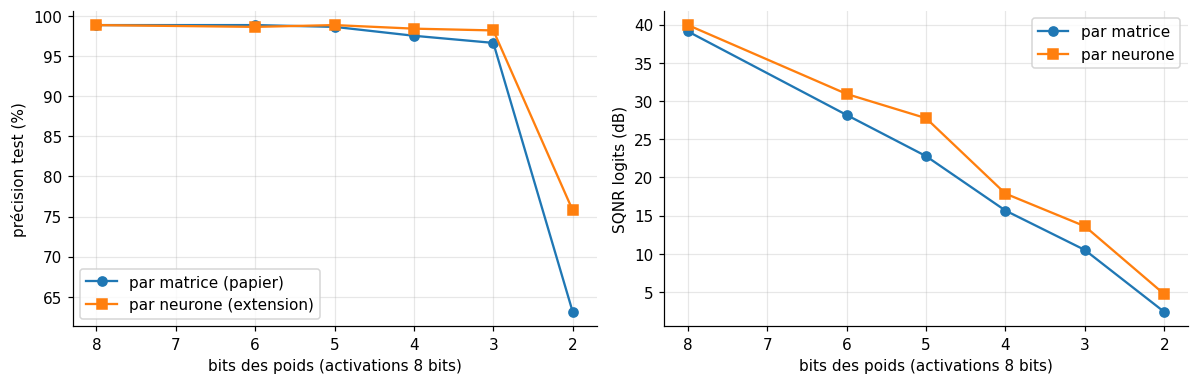

In [52]:
bit_list = [8, 6, 5, 4, 3, 2]
acc_t, acc_c, sq_t, sq_c = [], [], [], []
for b in bit_list:
    qt = QuantizedNet(net, Xtr, bits_w=b, bits_a=8, per_channel=False)
    qc = QuantizedNet(net, Xtr, bits_w=b, bits_a=8, per_channel=True)
    acc_t.append(accuracy(qt.predict(Xte), Yte)); acc_c.append(accuracy(qc.predict(Xte), Yte))
    sq_t.append(sqnr(logits_f, dequantize(qt.forward_int(Xte), qt.S_out, qt.Z_out)))
    sq_c.append(sqnr(logits_f, dequantize(qc.forward_int(Xte), qc.S_out, qc.Z_out)))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(bit_list, 100 * np.array(acc_t), "o-", label="par matrice (papier)")
axs[0].plot(bit_list, 100 * np.array(acc_c), "s-", label="par neurone (extension)")
axs[0].set_ylabel("précision test (%)")
axs[1].plot(bit_list, sq_t, "o-", label="par matrice"); axs[1].plot(bit_list, sq_c, "s-", label="par neurone")
axs[1].set_ylabel("SQNR logits (dB)")
for ax in axs: ax.invert_xaxis(); ax.set_xlabel("bits des poids (activations 8 bits)"); ax.legend()
plt.tight_layout(); plt.show()

**Lecture.** À 8 et 6 bits, les deux se valent. En dessous, l'échelle par neurone gagne 2 à 5 dB de SQNR et l'essentiel de la précision perdue : à 3 bits de poids, on reste à ~98 % au lieu de ~97 %, et à 2 bits on passe de ~63 % à ~76 %. Pourtant les plages par neurone ne diffèrent ici que d'un facteur 2 environ. Sur MobileNet, où le papier mesure des écarts de plus de 100×, le gain est bien plus spectaculaire : c'est pour cela que TFLite a ensuite adopté la quantification par canal pour les poids.

Coût : un multiplicateur $(M_0, n)$ et un zero-point par neurone au lieu d'un seul par couche, soit quelques octets.

## 11. Visualisation sur la spirale (TP7)

Retour au problème du TP7. On entraîne un réseau $2 \to 32 \to 32 \to 3$ (ReLU6), puis on trace les zones de décision du réseau flottant et de ses versions **entièrement entières** à 8, 4, 3 et 2 bits. C'est la figure la plus parlante pour une présentation : on voit la frontière se dégrader et se « pixeliser ».

Ici l'entrée est dans $[-1,1]$ : son zero-point vaut 128, ce qui illustre la quantification asymétrique et le rôle des corrections de l'éq. 7.

précision entraînement flottante : 0.993


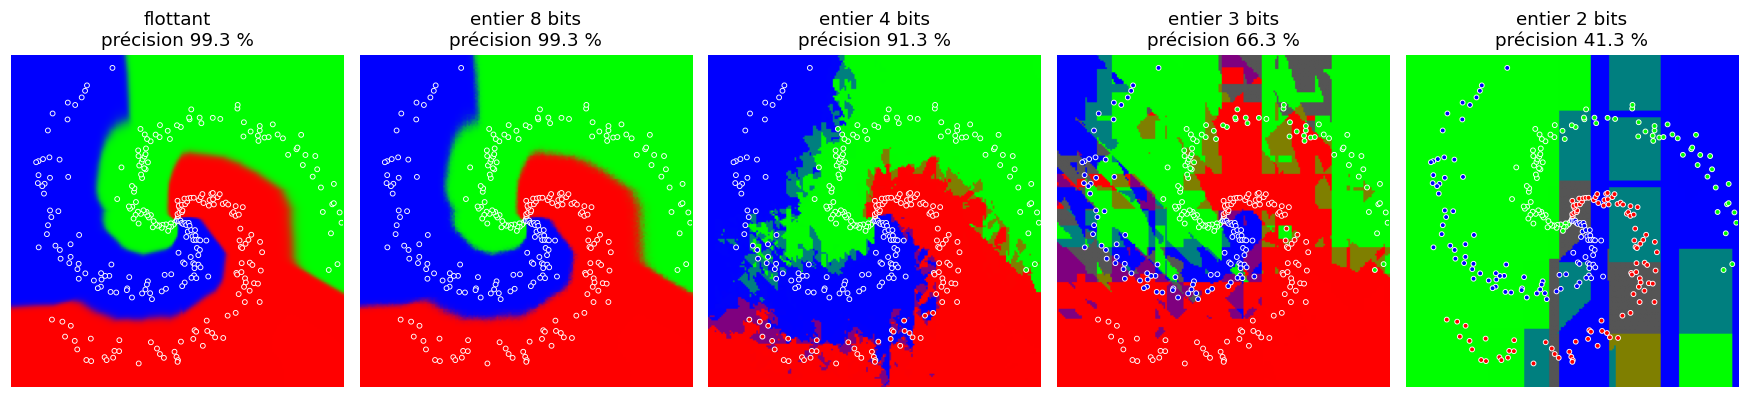

In [53]:
def make_spiral(n0=100, seed=0, noise=0.2):
    rng = np.random.default_rng(seed)
    X, Y = np.zeros((2, 3 * n0)), np.zeros((3, 3 * n0))
    for j in range(3):
        ind = np.arange(n0 * j, n0 * (j + 1))
        r = np.linspace(0, 1, n0)
        t = np.linspace(j * 4, (j + 1) * 4, n0) + rng.normal(0, noise, n0)
        X[0, ind], X[1, ind], Y[j, ind] = r * np.sin(t), r * np.cos(t), 1
    return X, Y

Xs, Ys = make_spiral()
np.random.seed(3)
net_s = make_mlp([2, 32, 32, 3], ReLU6)
h = train(net_s, Xs, Ys, epochs=1500, batch=64, lr=3e-3, seed=3)
print(f"précision entraînement flottante : {h['acc_train'][-1]:.3f}")

qq = 200
t = np.linspace(-1, 1, qq)
Yg, Xg = np.meshgrid(t, t)
G = np.vstack([Xg.ravel(), Yg.ravel()])
grid_calib = np.hstack([Xs, G])            # calibration : données + grille (entrée couvrant [-1,1]^2)

fig, axs = plt.subplots(1, 5, figsize=(16, 3.6))
cases = [("flottant", None)] + [(f"entier {b} bits", b) for b in [8, 4, 3, 2]]
for ax, (title, b) in zip(axs, cases):
    if b is None:
        U = sm.forward(net_s.forward(G)); acc = accuracy(net_s.forward(Xs), Ys)
    else:
        qn = QuantizedNet(net_s, grid_calib, b, b, bits_in=8)
        U = sm.forward(dequantize(qn.forward_int(G), qn.S_out, qn.Z_out)); acc = accuracy(qn.predict(Xs), Ys)
    ax.imshow(U.T.reshape(qq, qq, 3).transpose(1, 0, 2), origin="lower", extent=[-1, 1, -1, 1])
    ax.scatter(Xs[0], Xs[1], c=Ys.T, s=10, edgecolors="w", linewidths=0.6)
    ax.set_title(f"{title}\nprécision {100*acc:.1f} %"); ax.axis("off")
plt.tight_layout(); plt.show()

**Lecture.** À 8 bits, la carte est indiscernable de la version flottante. À 4 bits, la frontière devient irrégulière : avec seulement 16 niveaux sur chaque couche, le réseau ne peut plus représenter finement les variations d'une entrée 2D, alors que sur les chiffres (64 entrées redondantes) 4 bits suffisaient presque. À 3 et 2 bits, l'espace se découpe en rectangles : chaque neurone ne prend plus que quelques valeurs, et la fonction apprise devient constante par morceaux sur une grille grossière.

Cela illustre une idée importante : **la robustesse à la quantification dépend autant du problème que du réseau**. Un réseau surdimensionné pour sa tâche (les chiffres) absorbe le bruit grâce à sa redondance ; un réseau qui doit tracer une frontière fine dans un petit espace (la spirale) n'a pas cette marge. C'est l'argument du papier contre les évaluations sur AlexNet ou VGG.

## 12. Synthèse, limites, perspectives

### Ce qu'on a fait
| Section du papier | Implémentation dans ce notebook | Vérification |
|---|---|---|
| 2.1 Schéma affine $r = S(q-Z)$, 0 exact | `choose_qparams`, `quantize`, `dequantize` | erreur $\le S/2$, écart-type $S/\sqrt{12}$, 0 exact |
| 2.2 $M = 2^{-n}M_0$, virgule fixe | `quantize_multiplier`, `srdhm` (SQRDMULH), `rounding_divide_by_pot` | écart $\le 1$ avec l'arrondi flottant |
| 2.3 Zero-points factorisés (éq. 7-8) | `QDense.accumulate`, $\bar a_1$ précalculé hors ligne | égalité exacte avec le calcul naïf |
| 2.4 Couche fusionnée, biais int32, cast saturé, clamp | `QDense.forward`, `QuantizedNet` | inférence entière ≈ flottante, accumulateur < $2^{31}$ |
| Annexe B : arrondi correct | modes `nearest` / `half_up` / `floor` | le `>>` simple biaise chaque couche |

### Ce qu'on a appris sur la propagation
- L'erreur de quantification se comporte comme un **bruit additif indépendant** : le modèle $\mathbb E[\Delta u^2] \approx \frac{S_W^2}{12}\|x\|^2 + \frac{S_x^2}{12}\|W_i\|^2$ prédit la SQNR mesurée à 1-2 dB près.
- La SQNR relative d'une couche ne dépend pas de sa taille mais du **facteur de crête** (plage / RMS) de ses poids et de ses entrées. Les couches les plus touchées sont celles où quelques valeurs extrêmes, ou une entrée très creuse, étirent la plage.
- L'erreur **s'accumule** de couche en couche (les bruits s'additionnent en puissance). Les ReLU en effacent une partie.
- Une décision ne change que si l'erreur sur les logits dépasse la **marge** : les exemples mal classés après quantification sont ceux qui étaient déjà près de la frontière.
- Les **poids sont plus sensibles** que les activations à très bas nombre de bits, et **ReLU6 résiste mieux que ReLU** grâce à sa plage bornée : deux conclusions du papier retrouvées.
- 8 bits laisse une large marge : la perte est négligeable jusqu'à ~4-5 bits sur les chiffres, mais pas sur la spirale. La robustesse dépend de la redondance du réseau par rapport à sa tâche.
- Les détails comptent : un `>>` mal arrondi crée un biais qui se cumule de couche en couche ; l'échelle par neurone de sortie récupère l'essentiel de la précision à 2-3 bits. Le biais `int32` coûte presque rien et protège d'une erreur systématique, peu visible ici car nos biais sont petits.

### Limites
- **Vitesse.** NumPy n'a pas de produit matriciel `int8` optimisé : nos temps ne mesurent rien d'utile. Les gains du papier viennent du matériel (instructions SIMD `int8`, 4× moins de mémoire à déplacer). Ici, seul le gain mémoire (÷4) est mesuré.
- **Petit problème.** Les chiffres $8\times 8$ sont faciles, ce qui rend le réseau robuste. Le papier insiste sur ce point : quantifier un réseau surdimensionné est trivial, le vrai défi est un réseau déjà compact (MobileNet).
- **Post-training uniquement.** Les plages sont calibrées par min/max sur un lot ; un seul exemple extrême suffit à les étirer.

### Perspectives
1. **Section 3 du papier : entraînement avec quantification simulée (QAT).** Notre `sim_forward` est déjà la passe avant du QAT ; il resterait à rétropropager à travers `fake_quant` avec l'estimateur *straight-through* (gradient identité dans la plage, nul hors plage) et à suivre les plages d'activation par EMA. Le réseau apprendrait alors à placer ses poids sur la grille, ce qui devrait récupérer la précision à 4 bits.
2. **Repliement de la batch-norm** (éq. 14) si on ajoute une couche `BatchNorm` à la bibliothèque.
3. **Calibration plus robuste** : percentiles, minimisation de la MSE ou de la KL au lieu du min/max.
4. **Poids `int8` symétriques dans $[-127, 127]$** (section 3.1, annexe B) pour l'astuce d'accumulation sur 16 bits.